# Лекция 5. Деревья и бустинг

В L04 по финансовым индикаторам оценивали вероятность банкротства банка, при этом форму зависимости задавали мы: взвешенная сумма признаков внутри S-кривой (сигмоиды). Сегодня разберём модели, которые подбирают форму по данным:

1. **Дерево решений** (decision tree) делит отчёты на группы вопросами «признак меньше порога?».
2. **Случайный лес** (random forest) усредняет много деревьев.
3. **Градиентный бустинг** (gradient boosting) добавляет деревья по одному, и каждое исправляет ошибки суммы предыдущих. Откуда в названии градиент, посмотрим в п3.

В п5 посмотрим, что такие модели сообщают о риске, и соберём всё в интерактивный артефакт.

Под многими рисунками стоит клетка-ручка: поменяйте в ней число и перезапустите клетку. Рисунки plotly можно вращать и приближать, у анимаций есть кнопка ▶ и ползунок. Задача та же, что в L04: банкротство в течение года после отчёта.

## 0. Подготовка

Та же установочная ячейка, что в прошлых лекциях. Новая библиотека одна: plotly рисует интерактивные графики.

In [1]:
# Библиотеки для расчётов и графиков.
import numpy as np                          # массивы и математика
import pandas as pd                         # таблицы
import matplotlib.pyplot as plt             # статичные графики
import seaborn as sns                       # оформление графиков
import statsmodels.formula.api as smf       # регрессии по формуле "y ~ x"
import plotly.express as px                 # интерактивные графики одной строкой
import plotly.graph_objects as go           # интерактивные графики по частям: анимации, 3D
import plotly.io as pio                     # настройки plotly
from plotly.subplots import make_subplots   # несколько интерактивных графиков рядом
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss   # метрики из L04

# Откуда берём данные: файлы лежат в репозитории курса, читаем их прямо по ссылке.
DATA = "https://raw.githubusercontent.com/nvvoitov/da_intro/main/data/"

# Фиксируем случайность (сид): одно и то же число -> одинаковый результат при перезапуске
SEED = 20260101

# Косметика: параметры для отображения графиков. Вникать не обязательно.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)     # размер картинки по умолчанию
pd.set_option("display.max_columns", 30)    # показывать до 30 колонок таблицы
pio.templates.default = "plotly_white"      # светлый фон для plotly

In [2]:
# @title Помощники для рисунков: кнопка ▶ и понятные имена признаков
def add_player(fig, frame_names, prefix="", duration=600):
    # Кнопки «пуск» и «пауза» и ползунок по кадрам анимации
    steps = []
    for name in frame_names:
        steps.append(dict(label=str(name), method="animate",
                          args=[[str(name)], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                                  transition=dict(duration=0))]))
    play = dict(label="▶", method="animate",
                args=[None, dict(frame=dict(duration=duration, redraw=True), fromcurrent=True,
                                 transition=dict(duration=0))])
    pause = dict(label="❚❚", method="animate",
                 args=[[None], dict(mode="immediate", frame=dict(duration=0, redraw=False))])
    fig.update_layout(
        updatemenus=[dict(type="buttons", direction="left", x=0.08, y=0, xanchor="right", yanchor="top",
                          pad=dict(t=45, r=10), buttons=[play, pause])],
        sliders=[dict(active=0, x=0.08, len=0.92, y=0, yanchor="top", pad=dict(t=30, b=10),
                      currentvalue=dict(prefix=prefix), steps=steps)])
    return fig

def predict_p(model, data):
    # Вероятность события: у моделей sklearn — predict_proba, у statsmodels — predict
    if hasattr(model, "predict_proba"):
        return model.predict_proba(data)[:, 1]
    return np.asarray(model.predict(data))

# Русские подписи для признаков на рисунках
NAMES = {"c_equity_assets": "капитал / активы", "a_npl_gross_loans": "просрочка / кредиты",
         "m_cost_income": "расходы / доходы", "e_roa": "ROA",
         "l_brokered_share": "брокерские депозиты", "s_securities_assets": "ценные бумаги / активы"}

Данные, отбор, деление на обучение и тест и обрезку признаков повторяем из L04 §1 одной клеткой.

In [3]:
# Панель и отчёты, у которых известен исход за полный год (L04 §1.1)
panel = pd.read_parquet(DATA + "banks_panel.parquet")
panel = panel[panel["repdte"] <= pd.Timestamp("2025-06-30")].copy()

# Шесть признаков CAMELS из L04, активы > 50 млн $, без пропусков
FEATURES = ["c_equity_assets", "a_npl_gross_loans", "m_cost_income",
            "e_roa", "l_brokered_share", "s_securities_assets"]
df = panel[panel["assets"] > 50_000].dropna(subset=FEATURES).copy()
df["y"] = df["failed_next_4q"].astype(int)                 # 1 — банкротство в ближайший год

# 30 % банков целиком уходят в тест
shuffled = df["cert"].drop_duplicates().sample(frac=1, random_state=SEED)
test_certs = shuffled.iloc[:int(0.3 * len(shuffled))]
train = df[~df["cert"].isin(test_certs)].copy()
test = df[df["cert"].isin(test_certs)].copy()

# Обрезка по 1-му и 99-му перцентилям обучения
lower = train[FEATURES].quantile(0.01)
upper = train[FEATURES].quantile(0.99)
train[FEATURES] = train[FEATURES].clip(lower, upper, axis=1)
test[FEATURES] = test[FEATURES].clip(lower, upper, axis=1)

print("обучение:", len(train), "отчётов,", train["cert"].nunique(), "банков,", train["y"].sum(), "с событием")
print("тест:    ", len(test), "отчётов,", test["cert"].nunique(), "банков,", test["y"].sum(), "с событием")

обучение: 85442 отчётов, 1603 банков, 1453 с событием
тест:     36702 отчётов, 687 банков, 608 с событием


Эталон (бейслайн) для сравнения — логистическая регрессия из L04 на тех же шести признаках. Каждую модель лекции оценим на тех же тестовых банках тремя метриками из L04: AUC, AP и средним log loss на отчёт.

In [4]:
# Логистическая регрессия из L04 — эталон
logit6 = smf.logit("y ~ " + " + ".join(FEATURES), data=train).fit(disp=0)
test["p_logit"] = logit6.predict(test)

def scores(y, p):
    # Три метрики L04 для одних прогнозов
    return {"AUC": roc_auc_score(y, p), "AP": average_precision_score(y, p), "log loss": log_loss(y, p)}

results = {}                                         # сюда складываем метрики всех моделей на тесте
results["логит"] = scores(test["y"], test["p_logit"])
pd.DataFrame(results).T.round(4)

,AUC,AP,log loss
логит,0.9738,0.6556,0.032


### Log loss: штраф за уверенную ошибку

AUC и AP из L04 смотрят только на порядок отчётов. **Log loss** оценивает сами вероятности. Каждый отчёт получает штраф:

- если событие случилось ($y = 1$), штраф равен $-\ln p$;
- если не случилось ($y = 0$), штраф равен $-\ln(1 - p)$.

Log loss — среднее этих штрафов по всем отчётам, и чем он меньше, тем лучше:

$$\text{log loss} = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \ln p_i + (1 - y_i)\ln(1 - p_i)\Big].$$

Эту же сумму, только без деления на $n$, минимизирует логит (L04, приложение A).


In [5]:
# Ручка: штраф за один отчёт. Поменяйте прогноз и исход
p_one = 0.05          # прогноз модели: вероятность банкротства в течение года
y_one = 1             # что случилось: 1 — банкротство, 0 — нет

if y_one == 1:
    penalty = -np.log(p_one)          # событие было: штраф тем больше, чем меньше p
else:
    penalty = -np.log(1 - p_one)      # события не было: штраф тем больше, чем больше p
print(f"прогноз {p_one:.2%}, исход {y_one}: штраф {penalty:.3f}")

прогноз 5.00%, исход 1: штраф 2.996


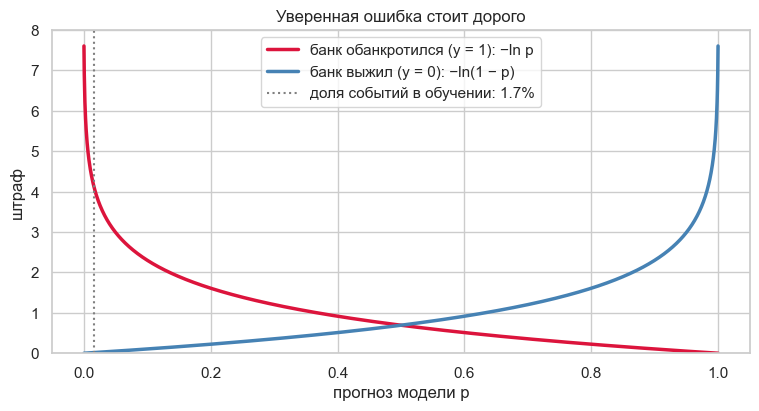

In [6]:
# @title Штраф за один отчёт в зависимости от прогноза
p_axis = np.linspace(0.0005, 0.9995, 2000)
plt.figure(figsize=(9, 4.2))
plt.plot(p_axis, -np.log(p_axis), color="crimson", lw=2.5, label="банк обанкротился (y = 1): −ln p")
plt.plot(p_axis, -np.log(1 - p_axis), color="steelblue", lw=2.5, label="банк выжил (y = 0): −ln(1 − p)")
base_rate = train["y"].mean()
plt.axvline(base_rate, color="gray", ls=":", label=f"доля событий в обучении: {base_rate:.1%}")
plt.ylim(0, 8)
plt.xlabel("прогноз модели p")
plt.ylabel("штраф")
plt.title("Уверенная ошибка стоит дорого")
plt.legend()
plt.show()

Уверенный верный прогноз почти ничего не стоит, уверенная ошибка стоит дорого. Если банк обанкротился, прогноз 5 % даёт штраф 3.0, прогноз 1 % — 4.6, прогноз 0.01 % — 9.2, и дальше штраф растёт без предела. Поэтому log loss строже всего наказывает модель, которая объявила банк безопасным, а он упал. Выжившие банки с малым прогнозом почти ничего не добавляют к среднему: при $p = 1\%$ штраф всего 0.01.

Посчитаем log loss логита на тесте вручную и сравним с моделью без признаков, которая всем отчётам даёт долю событий обучения.

In [7]:
p_test = test["p_logit"].to_numpy()      # прогнозы логита для тестовых отчётов
y_test = test["y"].to_numpy()            # их исходы 0/1

# Средний штраф по формуле выше — и то же самое через sklearn
by_hand = -np.mean(y_test * np.log(p_test) + (1 - y_test) * np.log(1 - p_test))
print(f"log loss вручную:  {by_hand:.4f}")
print(f"log loss sklearn:  {log_loss(y_test, p_test):.4f}")

# Модель без признаков: всем отчётам — доля событий в обучении
no_model = log_loss(y_test, np.full(len(y_test), train["y"].mean()))
print(f"без признаков:     {no_model:.4f}")

# Перевод в вероятность: среднее геометрическое вероятностей, данных фактическому исходу
print(f"exp(−log loss):    логит {np.exp(-by_hand):.3f}, без признаков {np.exp(-no_model):.3f}")

log loss вручную:  0.0320
log loss sklearn:  0.0320
без признаков:     0.0844
exp(−log loss):    логит 0.969, без признаков 0.919


Вручную получилось то же, что у sklearn: 0.0320. Модель без признаков даёт 0.0844, логит снижает средний штраф в 2.6 раза. Число можно перевести в вероятность: $e^{-0.0320} \approx 0.969$ — среднее геометрическое вероятностей, которые логит дал тому, что на самом деле случилось. У модели без признаков это 0.919.

Log loss удобен для сравнения моделей на одних и тех же отчётах. Его значение зависит от доли событий, поэтому между выборками с разной долей событий его напрямую не сравнивают. В п1 по этому критерию дерево выбирает пороги, в п4 бустинг подгоняет деревья.


## 1. Дерево: корзины, которые подбираются сами

### 1.1 Одно разбиение

В L04 п2 мы группировали банки по достаточности капитала вручную. Дерево же решений выбирает границу само. Начнём с одной границы по этой метрике: отчёты с капиталом ниже порога идут в левую группу, остальные в правую, и прогноз отчёта равен доле банкротств в его группе. Лучший порог даёт самый низкий log loss, тот же критерий, что у логита в L04.

Функция ниже рисует обе группы и log loss для всех порогов подряд.

In [8]:
# @title Функции для §1.1: одно разбиение по капиталу
x_cap = train["c_equity_assets"].to_numpy()        # капитал обучающих отчётов
y_cap = train["y"].to_numpy()                      # их метки 0/1

def split_log_loss(threshold):
    # Средний log loss, если прогноз отчёта — доля банкротств в его группе
    left = x_cap < threshold                       # True — отчёт в левой группе
    p_left = y_cap[left].mean()                    # доля банкротств слева
    p_right = y_cap[~left].mean()                  # доля банкротств справа
    p = np.where(left, p_left, p_right)            # прогноз для каждого отчёта
    return log_loss(y_cap, p), p_left, p_right

# Перебираем пороги от 3 до 20 % капитала шагом 0.1 п.п.
thresholds = np.round(np.arange(0.03, 0.2001, 0.001), 3)
split_losses = []
for t in thresholds:
    split_losses.append(split_log_loss(t)[0])
best_threshold = thresholds[np.argmin(split_losses)]

# Корзины капитала из L04 §2 — фон для рисунков
edges = [0, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10, 0.12, 0.15, 0.20, 1]
by_bin = train.groupby(pd.cut(train["c_equity_assets"], edges), observed=True).agg(
    equity=("c_equity_assets", "mean"), share_failed=("y", "mean"))

def show_split(threshold):
    loss, p_left, p_right = split_log_loss(threshold)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    # Слева: доли в корзинах L04 и два прогноза дерева
    ax1.scatter(by_bin["equity"], by_bin["share_failed"], color="black", s=40, zorder=5,
                label="доля банкротств в корзине L04")
    ax1.hlines(p_left, x_cap.min(), threshold, color="crimson", lw=3, label=f"левая группа: {p_left:.2%}")
    ax1.hlines(p_right, threshold, x_cap.max(), color="steelblue", lw=3, label=f"правая группа: {p_right:.2%}")
    ax1.axvline(threshold, color="gray", ls="--")
    ax1.set_xlabel("капитал / активы")
    ax1.set_ylabel("доля банкротств за год")
    ax1.set_title(f"Порог {threshold:.1%}: прогноз — доля в своей группе")
    ax1.legend()
    # Справа: log loss для всех порогов, ваш порог и минимум
    ax2.plot(thresholds, split_losses, color="steelblue", lw=2)
    ax2.scatter([threshold], [loss], color="crimson", s=70, zorder=5, label=f"ваш порог: {loss:.4f}")
    ax2.axvline(best_threshold, color="black", ls=":", label=f"минимум при {best_threshold:.1%}")
    ax2.set_xlabel("порог по капиталу")
    ax2.set_ylabel("средний log loss на обучении")
    ax2.set_title("Какой порог лучше разделяет отчёты?")
    ax2.legend()
    plt.tight_layout()
    plt.show()

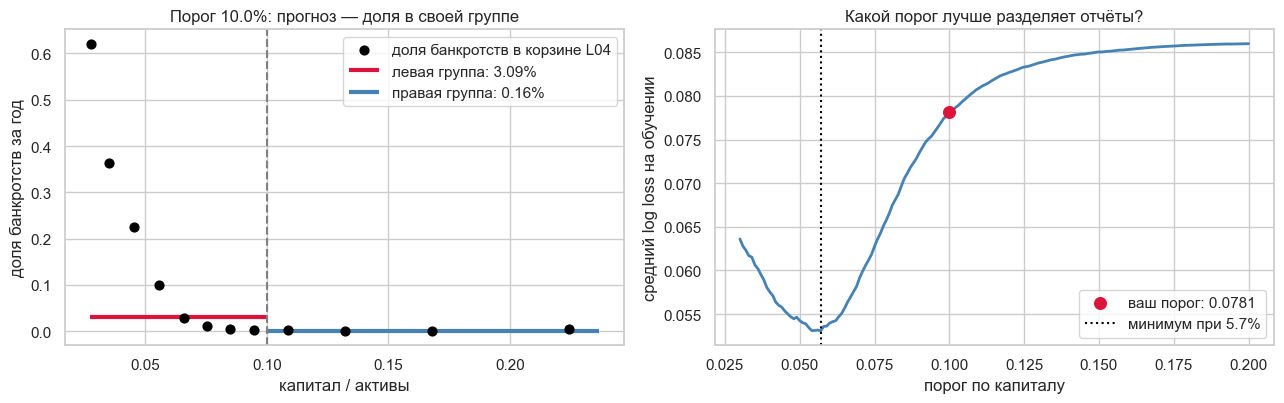

In [9]:
# Ручка: поменяйте порог (капитал / активы) и перезапустите клетку
threshold = 0.1
show_split(threshold)

При пороге 10 % в левую группу попали почти все опасные отчёты вместе с множеством здоровых: доля банкротств слева 3.1 %, справа 0.16 %. Подвигайте порог. Минимум log loss около 5.7 %: при более высоком пороге здоровые отчёты размывают левую группу, при более низком часть опасных уходит вправо.

Дерево глубины 1 (его называют пнём, stump) делает тот же перебор и находит почти тот же порог. Небольшая разница возникает из-за шага нашей сетки в 0.1 п.п.

In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree   # дерево решений и его схема

# Дерево глубины 1 — одно разбиение; criterion="log_loss" — тот же критерий, что на рисунке
stump = DecisionTreeClassifier(max_depth=1, criterion="log_loss")
stump.fit(train[["c_equity_assets"]], train["y"])

print(f"порог дерева:  {stump.tree_.threshold[0]:.4f}")
print(f"наш перебор:   {best_threshold:.4f}")

порог дерева:  0.0567
наш перебор:   0.0570


### 1.2 Дерево глубже

Каждую из двух групп можно снова разделить по тому же правилу, потом ещё раз. Число вопросов от корня до листа называют **глубиной** дерева. Ниже дерево глубины 2 на одном капитале.

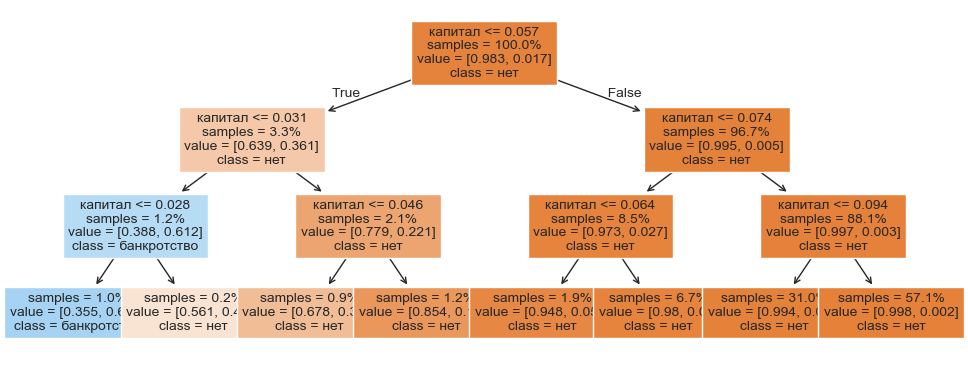

In [11]:
# Дерево глубины 2 на одном капитале
tree2 = DecisionTreeClassifier(max_depth=3, criterion="log_loss")
tree2.fit(train[["c_equity_assets"]], train["y"])

# proportion=True — доли вместо штук; impurity=False — не печатать log loss в узлах
plt.figure(figsize=(12, 4.5))
plot_tree(tree2, feature_names=["капитал"], class_names=["нет", "банкротство"],
          proportion=True, impurity=False, filled=True, precision=3, fontsize=10)
plt.show()

В прямоугольнике: вопрос, доля обучающих отчётов в узле (`samples`), доли классов «нет» и «банкротство» (`value`) и класс большинства. Ответ «да» (`True`) ведёт влево.

Первый вопрос тот же, что у пня: капитал не выше 5.7 %? Туда попали 3.3 % отчётов, и в 36 % из них банк обанкротился в течение года. Второй уровень даёт четыре корзины с границами 3.1 %, 5.7 % и 7.4 % и долями банкротств 61 %, 22 %, 2.7 % и 0.3 %.

Ручка ниже меняет глубину. Вертикальная шкала логарифмическая: каждое деление в 10 раз больше предыдущего.

In [12]:
# @title Функция для §1.2: ступеньки дерева и кривая логита
logit1 = smf.logit("y ~ c_equity_assets", data=train).fit(disp=0)        # логит с одним капиталом
cap_grid = pd.DataFrame({"c_equity_assets": np.linspace(x_cap.min(), x_cap.max(), 250)})

def show_tree_curve(max_depth):
    tree = DecisionTreeClassifier(max_depth=max_depth, criterion="log_loss")
    tree.fit(train[["c_equity_assets"]], train["y"])
    p_tree = tree.predict_proba(cap_grid)[:, 1]
    p_tree[p_tree == 0] = np.nan          # на логарифмической шкале ноль нарисовать нельзя
    plt.figure(figsize=(9, 4.5))
    plt.scatter(by_bin["equity"], by_bin["share_failed"], color="black", s=40, zorder=5, label="доля в корзине L04")
    plt.plot(cap_grid["c_equity_assets"], logit1.predict(cap_grid), color="steelblue", lw=2, label="логит с одним капиталом")
    plt.plot(cap_grid["c_equity_assets"], p_tree, color="crimson", lw=2.5,
             label=f"дерево глубины {max_depth}: {tree.get_n_leaves()} листьев")
    plt.yscale("log")
    plt.ylim(1e-4, 1.5)                   # ниже 0.01 % не рисуем: кривая логита уходит туда при высоком капитале
    plt.xlabel("капитал / активы")
    plt.ylabel("вероятность банкротства за год")
    plt.title("Дерево: прогноз меняется ступеньками")
    plt.legend()
    plt.show()

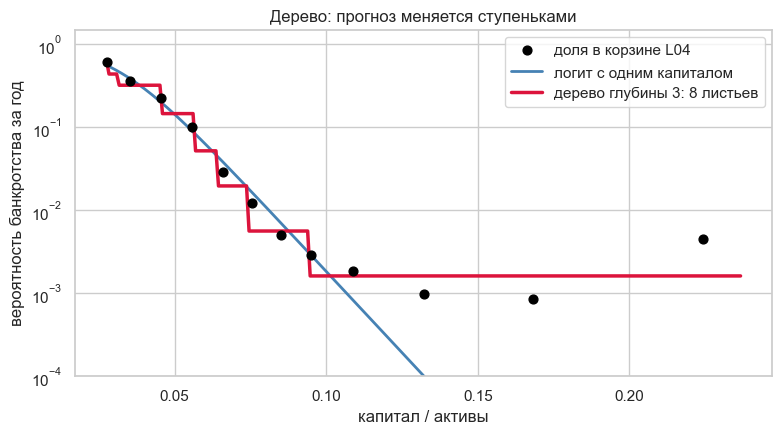

In [13]:
# Ручка: глубина дерева (1, 2, 3, ...). Шкала по вертикали логарифмическая
max_depth = 3
show_tree_curve(max_depth)

Логит с одним капиталом на такой шкале почти прямая. При капитале 11 % он обещает 0.07 %, а после 13 % уже меньше 0.01 %, хотя доли в корзинах L04 там держатся около 0.1–0.2 %. Дерево не связано формой, и ступенька справа стоит на уровне этих долей.

Прибавьте глубину: на глубине 3–4 ступеньки повторяют бакеты калибровки. При 8 появляются узкие всплески и провалы, а в разрывах линии прогноз равен ровно нулю (на логарифмической шкале ноль не рисуется): дерево подстраивается под отдельные отчёты.

### 1.3 Глубина и переобучение

Глубина — **гиперпараметр** (hyperparameter), как число соседей k в L01 и L03: глубокое дерево дробит отчёты на мелкие листья и запоминает обучающие данные. Теперь дерево получает все шесть признаков. Тест нужен для итогового сравнения, поэтому, как в L03, отложим внутри обучения 25 % банков в **валидационную выборку** (validation set). По ней же в п4 выберем число деревьев бустинга.

In [14]:
# Внутри обучения 25 % банков откладываем для выбора гиперпараметров; тест не трогаем
train_banks = train["cert"].drop_duplicates().sample(frac=1, random_state=SEED + 1)
valid_certs = train_banks.iloc[:int(0.25 * len(train_banks))]
fit = train[~train["cert"].isin(valid_certs)]          # на этих банках учим
valid = train[train["cert"].isin(valid_certs)]         # на этих выбираем гиперпараметры

depth_rows = []
for depth in range(1, 13):
    tree = DecisionTreeClassifier(max_depth=depth, criterion="log_loss", random_state=SEED)
    tree.fit(fit[FEATURES], fit["y"])
    for part, data in [("обучение", fit), ("валидация", valid)]:
        p = tree.predict_proba(data[FEATURES])[:, 1]
        depth_rows.append({"глубина": depth, "выборка": part,
                           "AUC": roc_auc_score(data["y"], p), "log loss": log_loss(data["y"], p)})
depth_table = pd.DataFrame(depth_rows)

# Два графика: AUC и log loss в зависимости от глубины
fig = make_subplots(rows=1, cols=2, subplot_titles=["AUC: выше — лучше", "log loss: ниже — лучше (шкала логарифмическая)"])
for part, color in [("обучение", "steelblue"), ("валидация", "crimson")]:
    part_rows = depth_table[depth_table["выборка"] == part]
    fig.add_trace(go.Scatter(x=part_rows["глубина"], y=part_rows["AUC"], name=part, line=dict(color=color)), row=1, col=1)
    fig.add_trace(go.Scatter(x=part_rows["глубина"], y=part_rows["log loss"], name=part, line=dict(color=color),
                             showlegend=False), row=1, col=2)
fig.update_yaxes(type="log", row=1, col=2)
fig.update_xaxes(title_text="глубина дерева")
fig.update_layout(height=420, width=1000)
fig.show()

# Лучшая глубина — минимум log loss на валидации
valid_rows = depth_table[depth_table["выборка"] == "валидация"].set_index("глубина")
best_depth = int(valid_rows["log loss"].idxmin())
print(f"лучшая глубина на валидации: {best_depth}, AUC {valid_rows.loc[best_depth, 'AUC']:.3f}, "
      f"log loss {valid_rows.loc[best_depth, 'log loss']:.4f}")
print(f"глубина 12 на валидации: AUC {valid_rows.loc[12, 'AUC']:.3f}, log loss {valid_rows.loc[12, 'log loss']:.3f}")

лучшая глубина на валидации: 4, AUC 0.964, log loss 0.0346
глубина 12 на валидации: AUC 0.838, log loss 0.406


На обучении обе метрики улучшаются с каждой новой глубиной, при глубине 12 AUC почти 1. На валидационных банках лучше всего глубина 4, дальше обе метрики ухудшаются, и при глубине 12 log loss почти в 12 раз больше. Log loss особенно чувствителен к листьям без единого события: прогноз в них равен нулю, и если отчёт нового банка из такого листа всё же заканчивается банкротством, штраф за уверенную ошибку огромен.

Дальше в сравнении моделей участвует дерево глубины 4.

## 2. Лес: усредняем дрожащие деревья

### 2.1 Дерево неустойчиво

Возьмём дерево глубины 4 на одном капитале и обучим его 200 раз на бутстрап-выборках банков, как в L03 п4: банки выбираем с возвращением, каждый вместе со всей его историей. Выборки похожи друг на друга, а ступеньки заметно прыгают.

In [15]:
# @title Расчёт: 200 деревьев глубины 4 на бутстрап-выборках банков
rng = np.random.default_rng(SEED)
bank_rows = train.groupby("cert").indices           # номер банка -> номера его строк в train
bank_ids = list(bank_rows.keys())

boot_curves = []
for b in range(200):
    chosen = rng.choice(len(bank_ids), size=len(bank_ids), replace=True)   # банки с возвращением
    positions = []
    for k in chosen:
        positions.append(bank_rows[bank_ids[k]])
    boot = train.iloc[np.concatenate(positions)]      # все отчёты выбранных банков
    tree = DecisionTreeClassifier(max_depth=4, criterion="log_loss").fit(boot[["c_equity_assets"]], boot["y"])
    boot_curves.append(tree.predict_proba(cap_grid)[:, 1])
boot_curves = np.array(boot_curves)                  # 200 строк — 200 ступенчатых кривых

def curve_trace(values, color, name, width=3, dash=None):
    values = np.where(values > 0, values, np.nan)     # ноль на логарифмической шкале не рисуем
    return go.Scatter(x=np.round(cap_grid["c_equity_assets"] * 100, 2), y=np.round(values, 6), mode="lines",
                      line=dict(color=color, width=width, dash=dash), name=name)

def base_figure():
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=np.round(by_bin["equity"] * 100, 2), y=by_bin["share_failed"], mode="markers",
                             marker=dict(color="black", size=8), name="доля в корзине L04"))
    fig.add_trace(curve_trace(logit1.predict(cap_grid).to_numpy(), "steelblue", "логит", width=2, dash="dot"))
    fig.update_yaxes(type="log", title="вероятность банкротства за год", range=[-4, 0])
    fig.update_xaxes(title="капитал / активы, %")
    fig.update_layout(height=480, width=950)
    return fig

def show_jumping_trees(n_frames=20):
    fig = base_figure()
    fig.add_trace(curve_trace(boot_curves[0], "crimson", "дерево на выборке"))
    frames = []
    for k in range(n_frames):
        frames.append(go.Frame(data=[curve_trace(boot_curves[k], "crimson", "дерево на выборке")],
                               traces=[2], name=str(k + 1)))
    fig.frames = frames
    fig.update_layout(title="Одно и то же дерево на разных бутстрап-выборках банков")
    add_player(fig, range(1, n_frames + 1), prefix="выборка ")
    fig.show()

def show_average(counts=(1, 2, 3, 5, 10, 20, 50, 100, 200)):
    fig = base_figure()
    fig.add_trace(curve_trace(boot_curves[0], "rgba(220,20,60,0.35)", "одно дерево", width=2))
    fig.add_trace(curve_trace(boot_curves[:1].mean(axis=0), "crimson", "среднее деревьев"))
    frames = []
    for n in counts:
        frames.append(go.Frame(data=[curve_trace(boot_curves[:n].mean(axis=0), "crimson", "среднее деревьев")],
                               traces=[3], name=str(n)))
    fig.frames = frames
    fig.update_layout(title="Среднее первых n деревьев")
    add_player(fig, counts, prefix="деревьев: ")
    fig.show()

show_jumping_trees()

Нажмите ▶. Выборки отличаются только тем, какие банки попали в них дважды, а какие не попали. Пороги при этом смещаются, иногда появляются узкие всплески: дерево отдаёт лист нескольким отчётам одного-двух банков. Небольшое изменение данных даёт заметно другое дерево.

### 2.2 Среднее многих деревьев

Если одно дерево дрожит, почему бы нам просто не усреднить все? Этот приём называют **бэггингом** (bagging, от bootstrap aggregating). Анимация показывает среднее первых 1, 2, 3, 5, … 200 деревьев из тех же выборок.

In [16]:
show_average()

К 200 деревьям прыжки отдельных деревьев гасят друг друга. Усреднение снижает разброс от выборки к выборке (variance); но то, в чём одинаково ошибаются все деревья, бэггинг не исправляет. Обратите внимание на подъём при капитале выше 20 %: его видит почти каждое дерево. Вернёмся к нему в п5.1.

Случайный лес добавляет вторую случайность: в каждом разбиении дерево выбирает вопрос среди случайно отобранных признаков (по умолчанию √6 ≈ 2 из 6). Деревья становятся менее похожими, и при усреднении их ошибки сильнее гасят друг друга. Сравним на тесте логит, дерево с глубиной из §1.3 и лес из 300 деревьев с типичными, не подобранными параметрами.

In [17]:
from sklearn.ensemble import RandomForestClassifier

# Дерево с глубиной, лучшей на валидации (§1.3), — обучаем на всём обучении
best_tree = DecisionTreeClassifier(max_depth=best_depth, criterion="log_loss", random_state=SEED)
best_tree.fit(train[FEATURES], train["y"])
results[f"дерево глубины {best_depth}"] = scores(test["y"], best_tree.predict_proba(test[FEATURES])[:, 1])

# Лес: 300 деревьев, в каждом листе не меньше 20 отчётов; n_jobs=-1 — считать на всех ядрах
forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
forest.fit(train[FEATURES], train["y"])
test["p_forest"] = forest.predict_proba(test[FEATURES])[:, 1]
results["лес"] = scores(test["y"], test["p_forest"])

# Сколько тестовых отчётов лес считает абсолютно безопасными — и сколько из них обанкротились
zero = test["p_forest"] == 0
print(f"прогноз ровно 0: {zero.mean():.0%} тестовых отчётов, из них с событием: {test.loc[zero, 'y'].sum()}")

pd.DataFrame(results).T.round(4)

прогноз ровно 0: 37% тестовых отчётов, из них с событием: 4


,AUC,AP,log loss
логит,0.9738,0.6556,0.0320
дерево глубины 4,0.9611,0.6060,0.0345
лес,0.9771,0.6609,0.0345


Лес идентифицирует риск-профиль лучше одного дерева и немного лучше логита: AUC 0.977 и AP 0.661 против 0.974 и 0.656. Но это разница в третьем знаке, и без бутстрапа она не доказана. По log loss лес чуть проигрывает логиту: 0.0345 против 0.0320. Причина в краях: для 37 % тестовых отчётов лес выдаёт ровно 0 (все 300 деревьев отправили их в листья без банкротств), а четыре таких отчёта всё же закончились банкротством. За уверенную ошибку log loss штрафует очень сильно, поэтому вероятности леса для решений пришлось бы калибровать (L04 §5).

## 3. Градиентный спуск

В L04 (приложение A) логит подбирал коэффициенты шагами вниз по чаше log loss. Бустинг тоже спускается, поэтому посмотрим на спуск там, где ответ известен заранее. Возьмём отчёты «обычных» банков с фильтром из L01 и будем предсказывать ROA в процентах по расходам / доходам и росту активов за год. Подгоняем на 1000 случайных отчётах, остальные оставляем для проверки.

In [18]:
# Фильтр «обычных» банков из L01
l01_rows = panel[(panel["assets"] > 50_000)
                 & panel["e_roa"].between(-0.10, 0.10)
                 & panel["m_cost_income"].between(0, 2)
                 & panel["a_nco_rate"].between(0, 0.05)
                 & panel["c_equity_assets"].between(0.02, 0.30)].dropna(subset=["m_asset_growth_yoy"])

roa_df = pd.DataFrame({"roa": l01_rows["e_roa"] * 100,                 # ROA, %
                       "cost_income": l01_rows["m_cost_income"],       # расходы / доходы, доля
                       "growth": l01_rows["m_asset_growth_yoy"] * 100})  # рост активов за год, %
roa_small = roa_df.sample(1000, random_state=SEED).copy()   # на этих отчётах рисуем и подгоняем
roa_rest = roa_df.drop(roa_small.index).copy()              # на остальных проверяем

# Рост активов обрезаем по 1-му и 99-му перцентилям выборки: слияния дают рост в сотни процентов
low, high = roa_small["growth"].quantile([0.01, 0.99])
roa_small["growth"] = roa_small["growth"].clip(low, high)
roa_rest["growth"] = roa_rest["growth"].clip(low, high)

y_roa = roa_small["roa"].to_numpy()                          # отклик выборки массивом
print("в выборке:", len(roa_small), "| на проверке:", len(roa_rest), f"| средний ROA в выборке: {y_roa.mean():.3f} %")

в выборке: 1000 | на проверке: 88199 | средний ROA в выборке: 0.803 %


### 3.1 Одна неизвестная

Самая простая модель — одно число $b$ для всех отчётов. Ошибка — средний квадрат остатка:

$$\text{MSE}(b) = \frac{1}{n}\sum_{i=1}^{n}(y_i - b)^2.$$

Из L02 известно, что лучшее $b$ равно среднему, но найдём его, не зная этого.

Наклон кривой MSE в точке $b$ — это производная:

$$\frac{d\,\text{MSE}}{db} = \frac{1}{n}\sum_{i=1}^{n} 2(y_i - b)\cdot(-1) = -2\cdot\overline{(y - b)}.$$

Черта сверху означает среднее по всем отчётам: $\overline{(y-b)} = \frac{1}{n}\sum_i (y_i - b)$, то есть средний остаток. Когда параметров несколько, набор таких производных называют **градиентом**, а направление против него — **антиградиентом**. С одним параметром градиент — это просто производная. Спуск шагает по антиградиенту:

$$b \leftarrow b - \eta\cdot\frac{d\,\text{MSE}}{db} = b + 2\eta\cdot\overline{(y-b)}.$$

Здесь $\eta$ («эта») — **темп обучения** (learning rate). В коде множитель 2 спрятан в темп, и шаг равен $\eta\cdot\overline{(y-b)}$. Если остатки в среднем положительны, значит, $b$ занижено, производная отрицательна, и шаг увеличивает $b$.

In [19]:
learning_rate = 0.3     # темп обучения: какую долю среднего остатка прибавляем за шаг
b = 3.0                 # стартовая догадка, %

for step in range(15):
    print(f"шаг {step + 1:2d}: b = {b:.4f} | среднее ROA: {y_roa.mean():.4f}")
    mean_residual = np.mean(y_roa - b)          # средний остаток при текущем b
    b = b + learning_rate * mean_residual       # шаг вниз по склону

print(f"после 15 шагов: {b:.4f} | среднее ROA: {y_roa.mean():.4f}")

шаг  1: b = 3.0000 | среднее ROA: 0.8031
шаг  2: b = 2.3409 | среднее ROA: 0.8031
шаг  3: b = 1.8796 | среднее ROA: 0.8031
шаг  4: b = 1.5566 | среднее ROA: 0.8031
шаг  5: b = 1.3306 | среднее ROA: 0.8031
шаг  6: b = 1.1723 | среднее ROA: 0.8031
шаг  7: b = 1.0616 | среднее ROA: 0.8031
шаг  8: b = 0.9840 | среднее ROA: 0.8031
шаг  9: b = 0.9298 | среднее ROA: 0.8031
шаг 10: b = 0.8918 | среднее ROA: 0.8031
шаг 11: b = 0.8652 | среднее ROA: 0.8031
шаг 12: b = 0.8466 | среднее ROA: 0.8031
шаг 13: b = 0.8335 | среднее ROA: 0.8031
шаг 14: b = 0.8244 | среднее ROA: 0.8031
шаг 15: b = 0.8180 | среднее ROA: 0.8031
после 15 шагов: 0.8135 | среднее ROA: 0.8031


In [20]:
# @title Функция для §3.1: шарик на параболе ошибки
def show_descent_1d(learning_rate, start, n_steps):
    # Путь спуска — тот же цикл, что выше
    path = [start]
    b = start
    for step in range(n_steps):
        b = b + learning_rate * np.mean(y_roa - b)
        path.append(b)
    path = np.array(path)

    # Парабола MSE(b) в окне ±4 п.п. вокруг среднего
    center = y_roa.mean()
    b_axis = np.linspace(center - 4, center + 4, 200)
    mse_axis = []
    for value in b_axis:
        mse_axis.append(np.mean((y_roa - value) ** 2))
    mse_path = []
    for value in path:
        mse_path.append(np.mean((y_roa - value) ** 2))

    def frame_title(k):
        inside = abs(path[k] - center) <= 4
        where = "" if inside else " — шарик за краем рисунка"
        return f"шаг {k}: b = {path[k]:.3f}, MSE = {mse_path[k]:.3f}{where}"

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=b_axis, y=mse_axis, mode="lines", line=dict(color="steelblue", width=3), name="MSE(b)"))
    fig.add_trace(go.Scatter(x=path[:1], y=mse_path[:1], mode="lines+markers", name="путь",
                             line=dict(color="darkorange", width=1.5), marker=dict(size=6)))
    fig.add_trace(go.Scatter(x=path[:1], y=mse_path[:1], mode="markers", name="шарик",
                             marker=dict(size=18, color="crimson")))
    frames = []
    for k in range(n_steps + 1):
        frames.append(go.Frame(data=[go.Scatter(x=path[:k + 1], y=mse_path[:k + 1]),
                                     go.Scatter(x=path[k:k + 1], y=mse_path[k:k + 1])],
                               traces=[1, 2], name=str(k), layout=go.Layout(title_text=frame_title(k))))
    fig.frames = frames
    fig.add_vline(x=center, line_dash="dot", line_color="black")
    fig.update_xaxes(range=[center - 4, center + 4], title="b, % (прогноз ROA для всех отчётов)")
    fig.update_yaxes(range=[0, max(mse_axis) * 1.05], title="MSE")
    fig.update_layout(title=frame_title(0), height=450, width=900)
    add_player(fig, range(n_steps + 1), prefix="шаг ", duration=500)
    fig.show()

In [21]:
# Ручки: темп обучения, старт и число шагов. Нажмите ▶ под рисунком
learning_rate = 1.5
start = 3.0
n_steps = 15
show_descent_1d(learning_rate, start, n_steps)

Попробуйте темпы 0.05 (шарик ползёт), 1 (сразу в дно: шаг ровно равен среднему остатку), 1.8 (перелетает дно и качается, раскачка затухает) и 2.1 (каждый перелёт дальше предыдущего, спуск расходится). Та же картина будет у бустинга в §4.4.

### 3.2 Рельеф с каньонами

У линейной регрессии ошибка — одна чаша, как RSS в L02: откуда ни начни, спуск придёт в МНК. Если параметр сидит внутри нелинейной функции, рельеф ошибки становится изрезанным. Пример на тех же данных — «мягкая ступенька» ROA по росту активов:

$$\widehat{\text{ROA}} = c + \frac{h}{1 + e^{-(\text{рост} - t)/3}}.$$

До порога $t$ прогноз равен $c$, после него $c + h$, переход плавный, шириной несколько п.п. роста. Уровень $c$ подбираем сразу, чтобы параметров осталось два и ошибку можно было нарисовать. В коде порог меряется в десятках процентов роста, чтобы оба параметра были одного масштаба, как после стандартизации в L03 §8.

Наклон ошибки считаем численно: сдвигаем параметр на крошечную величину в обе стороны и смотрим, как изменилась ошибка. Пара наклонов по $t$ и по $h$ — это **градиент**, а шаг делаем против него, по **антиградиенту**.

In [22]:
growth10 = roa_small["growth"].to_numpy() / 10        # рост активов в десятках процентов: оба параметра одного масштаба

def step_loss(t, h):
    # MSE мягкой ступеньки: до порога t прогноз c, после — c + h
    step = h / (1 + np.exp(-(growth10 - t) / 0.3))      # плавный переход шириной около 3 п.п. роста
    c = np.mean(y_roa - step)                            # уровень до ступеньки подбираем сразу
    return np.mean((y_roa - c - step) ** 2)

def gradient(t, h, eps=1e-4):
    # Производная численно: как меняется ошибка при крошечном сдвиге каждого параметра
    d_t = (step_loss(t + eps, h) - step_loss(t - eps, h)) / (2 * eps)
    d_h = (step_loss(t, h + eps) - step_loss(t, h - eps)) / (2 * eps)
    return np.array([d_t, d_h])

def descend(start, learning_rate, n_steps):
    # Спуск по антиградиенту из точки start = (t, h); возвращает путь
    w = np.array(start, dtype=float)
    path = [w.copy()]
    for step in range(n_steps):
        w = w - learning_rate * gradient(w[0], w[1])     # шаг против наклона
        path.append(w.copy())
    return np.array(path)


In [23]:
# @title Функция для §3.2: рельеф ошибки, стрелки антиградиента и шарики
t_axis = np.linspace(-1.5, 9, 70)                       # порог, десятки процентов роста
h_axis = np.linspace(-1.2, 2.0, 64)                     # высота ступеньки, п.п. ROA
canyon = np.zeros((len(h_axis), len(t_axis)))
for i in range(len(h_axis)):
    for j in range(len(t_axis)):
        canyon[i, j] = step_loss(t_axis[j], h_axis[i])
floor = canyon.min()
def relief(v):
    return np.log10(v - floor + 0.002)                  # логарифм подчёркивает дно долин

CANYON_COLORS = [[0, "#15394a"], [0.3, "#3f7f7a"], [0.55, "#d9b77e"], [0.8, "#b5562e"], [1, "#f3e2c3"]]
BALL_COLORS = ["crimson", "darkorange", "gold", "deepskyblue", "violet", "limegreen", "black"]

def show_canyon(starts, learning_rate, n_steps):
    paths = []
    for start in starts:
        paths.append(descend(start, learning_rate, n_steps))
    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "xy"}]], column_widths=[0.55, 0.45],
                        subplot_titles=["рельеф ошибки (можно вращать)", "вид сверху: стрелки — антиградиент"])
    fig.add_trace(go.Surface(x=t_axis * 10, y=h_axis, z=relief(canyon), colorscale=CANYON_COLORS, showscale=False,
                             hoverinfo="skip"), row=1, col=1)
    fig.add_trace(go.Contour(x=t_axis * 10, y=h_axis, z=relief(canyon), colorscale=CANYON_COLORS, showscale=False,
                             ncontours=24, line_width=0.5, hoverinfo="skip"), row=1, col=2)
    # Стрелки антиградиента на редкой сетке: куда покатится шарик из этой точки
    xs, ys = [], []
    for t in np.linspace(-1, 8.5, 13):
        for h in np.linspace(-1, 1.8, 11):
            d = -gradient(t, h)
            length = np.hypot(d[0] / 10.5, d[1] / 3.2) + 1e-12   # длина в долях рамки
            xs += [t * 10, t * 10 + d[0] / length / 10.5 * 0.035 * 105, None]
            ys += [h, h + d[1] / length / 3.2 * 0.035 * 3.2, None]
    fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines+markers", line=dict(color="white", width=1),
                             marker=dict(symbol="arrow", size=[0, 7, 0] * (len(xs) // 3), angleref="previous", color="white"),
                             hoverinfo="skip", showlegend=False), row=1, col=2)
    first = len(fig.data)
    for p, color in zip(paths, BALL_COLORS):
        heights = relief(np.array([step_loss(w[0], w[1]) for w in p])) + 0.04
        fig.add_trace(go.Scatter3d(x=p[:1, 0] * 10, y=p[:1, 1], z=heights[:1], mode="lines+markers",
                                   line=dict(color=color, width=6), marker=dict(size=[6], color=color)), row=1, col=1)
        fig.add_trace(go.Scatter(x=p[:1, 0] * 10, y=p[:1, 1], mode="lines+markers", line=dict(color=color, width=2.5),
                                 marker=dict(size=[10], color=color, line=dict(color="white", width=1.5))), row=1, col=2)
    frames = []
    shown = list(range(0, n_steps + 1, max(1, n_steps // 30)))
    if shown[-1] != n_steps:
        shown.append(n_steps)
    for k in shown:
        data, traces = [], []
        for m, p in enumerate(paths):
            heights = relief(np.array([step_loss(w[0], w[1]) for w in p[:k + 1]])) + 0.04
            sizes = [0] * k + [6]
            data.append(go.Scatter3d(x=p[:k + 1, 0] * 10, y=p[:k + 1, 1], z=heights, marker=dict(size=sizes)))
            data.append(go.Scatter(x=p[:k + 1, 0] * 10, y=p[:k + 1, 1], marker=dict(size=[0] * k + [10])))
            traces += [first + 2 * m, first + 2 * m + 1]
        frames.append(go.Frame(data=data, traces=traces, name=str(k)))
    fig.frames = frames
    fig.update_layout(height=580, width=1150, showlegend=False,
                      scene=dict(xaxis_title="порог t, % роста", yaxis_title="высота h, п.п.", zaxis_title="ошибка",
                                 zaxis=dict(showticklabels=False), camera=dict(eye=dict(x=-1.5, y=-1.6, z=1.3))))
    fig.update_xaxes(title_text="порог t, % роста активов", range=[t_axis[0] * 10, t_axis[-1] * 10], row=1, col=2)
    fig.update_yaxes(title_text="высота ступеньки h, п.п. ROA", range=[h_axis[0], h_axis[-1]], row=1, col=2)
    add_player(fig, shown, prefix="шаг ", duration=250)
    fig.show()
    for p, color in zip(paths, BALL_COLORS):
        print(f"{color:>11}: старт t = {p[0, 0] * 10:5.1f} %, h = {p[0, 1]:5.2f} -> "
              f"финиш t = {p[-1, 0] * 10:5.1f} %, h = {p[-1, 1]:5.2f}, MSE {step_loss(p[-1, 0], p[-1, 1]):.4f}")


In [ ]:
# Ручки: стартовые точки (t в десятках процентов роста, h в п.п. ROA), темп и число шагов. Нажмите ▶
starts = [(0.5, 0.3), (1.5, 0.3), (4.5, 0.2), (6.0, -0.6), (8.0, 0.5)]
learning_rate = 2.0
n_steps = 150
show_canyon(starts, learning_rate, n_steps)

    crimson: старт t =   5.0 %, h =  0.30 -> финиш t =  -6.0 %, h =  1.51, MSE 1.2401
 darkorange: старт t =  15.0 %, h =  0.30 -> финиш t =  -6.0 %, h =  1.51, MSE 1.2401
       gold: старт t =  45.0 %, h =  0.20 -> финиш t =  45.7 %, h = -0.06, MSE 1.3214
deepskyblue: старт t =  60.0 %, h = -0.60 -> финиш t =  72.4 %, h = -0.66, MSE 1.3141
     violet: старт t =  80.0 %, h =  0.50 -> финиш t =  77.5 %, h = -0.76, MSE 1.3136


Пять шариков стартуют в разных местах и приходят в разные точки:

- красный и оранжевый (старты у порога 5 и 15 %) скатываются в глубокий каньон: порог −6 %, ступенька вверх на 1.5 п.п. По этой ступеньке банки, чьи активы за год сократились больше чем на 6 %, зарабатывают на 1.5 п.п. ROA меньше остальных. Это лучшая ступенька на этих данных (MSE 1.240);
- голубой и розовый уходят в мелкую долину при пороге 72–78 % со ступенькой вниз (MSE около 1.314): сверхбыстрый рост тоже снижает ROA, но слабее;
- жёлтый застревает на плато около 45 %: наклон там почти нулевой, и шаги почти не двигают шарик (MSE 1.321).

Градиентный спуск находит локальный минимум (ближайшее дно), а глобальный. Поэтому дерево в §1 выбирало порог перебором всех значений. Бустинг использует градиент там, где рельеф — одна чаша: ошибка как функция прогнозов (квадрат остатка или log loss) выпукла. Пороги его деревьев по-прежнему ищутся перебором.

Попробуйте добавить свою точку в `starts` или поменять темп. При `learning_rate = 0.5` шарики не успевают доехать за 150 шагов. При `learning_rate = 12` оранжевый перепрыгивает хребет и оказывается в дальней долине у 77 %, а красный вылетает за край рисунка.

## 4. Бустинг: простые модели складываются в сложную форму

### 4.1 Модель учится на ошибках предыдущей

Объясним ROA тех же отчётов по раундам. Первая слабая модель — квадрат по одному признаку. Следующая подгоняется к её ошибкам, третья — к ошибкам суммы двух, и так дальше: на каждом раунде берём ошибки суммы, собранной к этому моменту, подгоняем к ним квадрат по одному признаку и прибавляем его к сумме. Признак выбираем тот, по которому квадрат лучше всего объясняет ошибки. Кандидатов десять: расходы / доходы, рост активов и ещё восемь отношений из панели. Один и тот же признак можно брать повторно.

In [25]:
def rmse(residual):
    # Корень из среднего квадрата остатка — типичная ошибка в п.п. ROA
    return np.sqrt(np.mean(residual ** 2))

line1 = smf.ols("roa ~ cost_income", data=roa_small).fit()     # прямая МНК по расходам / доходам — для сравнения в §4.2

In [26]:
# Ещё восемь отношений из той же панели: слабым моделям будет из чего выбирать
EXTRA = {"e_nim": "nim", "a_nco_rate": "nco", "a_npl_gross_loans": "npl", "c_equity_assets": "capital",
         "l_loans_deposits": "loans_deposits", "l_liquid_assets_ratio": "liquid",
         "s_securities_assets": "securities", "a_cre_concentration": "cre"}
for column, name in EXTRA.items():
    roa_small[name] = l01_rows.loc[roa_small.index, column] * 100     # в процентах
    roa_rest[name] = l01_rows.loc[roa_rest.index, column] * 100
    lo_x, hi_x = roa_small[name].quantile([0.01, 0.99])              # границы обрезки — по выборке
    roa_small[name] = roa_small[name].clip(lo_x, hi_x)
    roa_rest[name] = roa_rest[name].clip(lo_x, hi_x)
CHAIN_FEATURES = ["cost_income", "growth"] + list(EXTRA.values())

y_rest = roa_rest["roa"].to_numpy()
F = np.full(len(y_roa), y_roa.mean())                   # раунд 0: прогноз для всех — среднее
F_rest = np.full(len(roa_rest), y_roa.mean())
chain, history = [], []
for round_no in range(1, 13):
    residual = y_roa - F                                # ошибки суммы, собранной к этому раунду
    best = None
    for feature in CHAIN_FEATURES:                      # пробуем квадрат по каждому признаку
        data = pd.DataFrame({"r": residual, "x": roa_small[feature].to_numpy()})
        weak = smf.ols("r ~ x + I(x ** 2)", data=data).fit()
        if best is None or weak.ssr < best[1].ssr:      # оставляем тот, что лучше всего объяснил ошибки
            best = (feature, weak)
    feature, weak = best
    F = F + weak.fittedvalues.to_numpy()                # добавляем слабую модель к сумме
    F_rest = F_rest + weak.predict(pd.DataFrame({"x": roa_rest[feature].to_numpy()})).to_numpy()
    history.append((feature, residual, weak))           # для рисунка
    chain.append({"раунд": round_no, "признак": feature,
                  "RMSE выборка": rmse(y_roa - F), "RMSE проверка": rmse(y_rest - F_rest)})
pd.DataFrame(chain).set_index("раунд").round(4)


,признак,RMSE выборка,RMSE проверка
раунд,,,
1,cost_income,1.0042,1.0545
2,nco,0.9071,0.9627
3,nim,0.8723,0.9260
4,liquid,0.8532,0.9209
5,cost_income,0.8354,0.9058
6,npl,0.8239,0.8912
7,cre,0.8177,0.8900
8,nim,0.8141,0.8827
9,cost_income,0.8109,0.8836


In [27]:
# @title Функция для §4.1: цепочка слабых моделей по раундам
CHAIN_NAMES = {"cost_income": "расходы / доходы", "growth": "рост активов, %", "nim": "процентная маржа, %",
               "nco": "списания / кредиты, %", "npl": "просрочка / кредиты, %", "capital": "капитал / активы, %",
               "loans_deposits": "кредиты / депозиты, %", "liquid": "ликвидные активы, %",
               "securities": "ценные бумаги / активы, %", "cre": "коммерческая недвижимость / кредиты, %"}

def show_chain(history, chain):
    # Для сравнения: одна регрессия сразу на всех признаках с квадратами
    formula = "roa ~ " + " + ".join(f"{f} + I({f} ** 2)" for f in CHAIN_FEATURES)
    joint = smf.ols(formula, data=roa_small).fit()
    joint_check = rmse(y_rest - joint.predict(roa_rest).to_numpy())

    rounds = [0] + [row["раунд"] for row in chain]
    rmse_small = [rmse(y_roa - y_roa.mean())] + [row["RMSE выборка"] for row in chain]
    rmse_check = [rmse(y_rest - y_roa.mean())] + [row["RMSE проверка"] for row in chain]
    low, high = np.quantile(history[0][1], [0.01, 0.99])

    def left_data(k):
        feature, residual, weak = history[k]
        x = roa_small[feature].to_numpy()
        grid = np.linspace(x.min(), x.max(), 100)
        curve = weak.predict(pd.DataFrame({"x": grid})).to_numpy()
        return x, residual, grid, curve

    def title(k):
        feature = history[k][0]
        return (f"раунд {k + 1}: квадрат по признаку «{CHAIN_NAMES[feature]}» | "
                f"RMSE на проверке {rmse_check[k]:.3f} → {rmse_check[k + 1]:.3f}")

    fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45],
                        subplot_titles=["ошибки суммы и новая слабая модель", "ошибка сильной модели по раундам"])
    x, residual, grid, curve = left_data(0)
    fig.add_trace(go.Scatter(x=x, y=np.round(residual, 3), mode="markers", marker=dict(size=4, color="gray", opacity=0.4),
                             showlegend=False), row=1, col=1)
    fig.add_trace(go.Scatter(x=grid, y=curve, mode="lines", line=dict(color="crimson", width=3), showlegend=False),
                  row=1, col=1)
    fig.add_trace(go.Scatter(x=rounds, y=rmse_small, mode="lines+markers", line=dict(color="steelblue"), name="выборка"),
                  row=1, col=2)
    fig.add_trace(go.Scatter(x=rounds, y=rmse_check, mode="lines+markers", line=dict(color="crimson"), name="проверка"),
                  row=1, col=2)
    fig.add_trace(go.Scatter(x=[0, rounds[-1]], y=[joint_check, joint_check], mode="lines",
                             line=dict(color="black", dash="dot"), name="одна регрессия на всех<br>признаках (проверка)"),
                  row=1, col=2)
    fig.add_trace(go.Scatter(x=[1, 1], y=[rmse_small[1], rmse_check[1]], mode="markers",
                             marker=dict(size=14, color="black", symbol="circle-open", line=dict(width=2)),
                             showlegend=False), row=1, col=2)
    frames = []
    for k in range(len(history)):
        x, residual, grid, curve = left_data(k)
        frames.append(go.Frame(data=[go.Scatter(x=x, y=np.round(residual, 3)), go.Scatter(x=grid, y=curve),
                                     go.Scatter(x=[k + 1, k + 1], y=[rmse_small[k + 1], rmse_check[k + 1]])],
                               traces=[0, 1, 5], name=str(k + 1),
                               layout=go.Layout(title_text=title(k), xaxis=dict(title_text=CHAIN_NAMES[history[k][0]]))))
    fig.frames = frames
    fig.update_yaxes(range=[low, high], title_text="ошибка, п.п. ROA", row=1, col=1)
    fig.update_xaxes(title_text=CHAIN_NAMES[history[0][0]], row=1, col=1)
    fig.update_xaxes(title_text="раунд", dtick=1, row=1, col=2)
    fig.update_yaxes(title_text="RMSE, п.п. ROA", row=1, col=2)
    fig.update_layout(title=title(0), height=500, width=1150,
                      legend=dict(x=0.99, y=0.97, xanchor="right", yanchor="top"))
    add_player(fig, range(1, len(history) + 1), prefix="раунд ", duration=900)
    fig.show()
    print(f"одна регрессия со всеми квадратами сразу: выборка {rmse(joint.resid):.4f}, проверка {joint_check:.4f}")


In [28]:
show_chain(history, chain)


одна регрессия со всеми квадратами сразу: выборка 0.8023, проверка 0.8773


Нажмите ▶. Слева ошибки суммы перед раундом против выбранного признака и слабая модель, которая к ним подгоняется. Справа ошибка суммы после каждого раунда.

Первая модель, квадрат по расходам / доходам, снижает ошибку на проверке с 1.223 до 1.054. Вторая берёт списания: у банков с большими списаниями ROA ниже, чем предсказала первая модель, и ошибка падает до 0.963. Третья добавляет процентную маржу: 0.926. Дальше каждая модель добавляет всё меньше, и к 12-му раунду ошибка на проверке 0.874. Это на уровне одной большой регрессии на всех признаках с квадратами (0.877), хотя каждая слабая модель смотрит на один признак. Расходы / доходы выбраны трижды: после других моделей в ошибках по ним снова появляется закономерность.

Это и есть идея бустинга: слабые модели учатся по очереди, каждая на ошибках суммы предыдущих. Здесь каждую модель прибавляем целиком; в бустинге её обычно берут с темпом $\eta < 1$. Дальше вместо квадратов будут маленькие деревья, которые сами выбирают и признак, и форму.

### 4.2 Ступеньки вместо прямых

Бустинг делает то же самое, только каждая следующая модель — маленькое дерево глубины 1–3, которое само выбирает признак и порог. Цикл из трёх шагов: посчитать остатки текущей суммы, подогнать к ним дерево, прибавить его прогноз к сумме с темпом $\eta$, как в §3. Сначала один признак, расходы / доходы, и деревья глубины 1 («пни», stumps).

In [29]:
from sklearn.tree import DecisionTreeRegressor             # дерево для чисел: в листе — средний остаток

X_ci = roa_small[["cost_income"]]                          # один признак
F = np.full(len(y_roa), y_roa.mean())                      # старт: среднее, как в §3.1
learning_rate = 0.3

for m in range(50):                                        # 50 деревьев по очереди
    residual = y_roa - F                                   # 1. что осталось объяснить
    stump = DecisionTreeRegressor(max_depth=1).fit(X_ci, residual)    # 2. ступенька ловит остатки
    F = F + learning_rate * stump.predict(X_ci)            # 3. прибавляем её с темпом

print(f"RMSE после 50 ступенек: {rmse(y_roa - F):.4f} | у прямой: {rmse(line1.resid):.4f}")

# Готовый бустинг sklearn с теми же настройками даёт тот же прогноз
from sklearn.ensemble import GradientBoostingRegressor
sk_booster = GradientBoostingRegressor(n_estimators=50, learning_rate=0.3, max_depth=1).fit(X_ci, y_roa)
print(f"наибольшее расхождение с нашим циклом: {np.abs(sk_booster.predict(X_ci) - F).max():.1e}")

RMSE после 50 ступенек: 0.9599 | у прямой: 1.0047
наибольшее расхождение с нашим циклом: 3.2e-10


In [30]:
# @title Функция для §4.2: бустинг шаг за шагом
def show_boosting_1d(learning_rate, max_depth, n_trees):
    ci_grid = pd.DataFrame({"cost_income": np.linspace(roa_small["cost_income"].min(), roa_small["cost_income"].max(), 300)})
    F = np.full(len(y_roa), y_roa.mean())
    F_grid = np.full(len(ci_grid), y_roa.mean())
    snapshots = {}
    shown = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 500]
    for m in range(1, n_trees + 1):
        residual = y_roa - F
        tree = DecisionTreeRegressor(max_depth=max_depth).fit(X_ci, residual)
        F = F + learning_rate * tree.predict(X_ci)
        F_grid = F_grid + learning_rate * tree.predict(ci_grid)
        if m in shown or m == n_trees:
            snapshots[m] = (residual.copy(), tree.predict(ci_grid), F_grid.copy(), rmse(y_roa - F))

    x_grid = ci_grid["cost_income"]
    first = min(snapshots)
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.6, 0.4], vertical_spacing=0.08,
                        subplot_titles=["данные и сумма деревьев", "остатки перед деревом и само дерево"])
    fig.add_trace(go.Scatter(x=roa_small["cost_income"], y=np.round(y_roa, 3), mode="markers",
                             marker=dict(size=4, color="gray", opacity=0.4), name="отчёты"), row=1, col=1)
    fig.add_trace(go.Scatter(x=x_grid, y=line1.predict(ci_grid), mode="lines", name="прямая МНК",
                             line=dict(color="steelblue", dash="dash")), row=1, col=1)
    fig.add_trace(go.Scatter(x=x_grid, y=np.round(snapshots[first][2], 4), mode="lines", name="сумма деревьев",
                             line=dict(color="crimson", width=3)), row=1, col=1)
    fig.add_trace(go.Scatter(x=roa_small["cost_income"], y=np.round(snapshots[first][0], 3), mode="markers",
                             marker=dict(size=4, color="slategray", opacity=0.4), name="остатки"), row=2, col=1)
    fig.add_trace(go.Scatter(x=x_grid, y=np.round(snapshots[first][1], 4), mode="lines", name="новое дерево",
                             line=dict(color="darkorange", width=3)), row=2, col=1)
    frames = []
    for m, (residual, tree_line, sum_line, error) in snapshots.items():
        frames.append(go.Frame(data=[go.Scatter(y=np.round(sum_line, 4)), go.Scatter(y=np.round(residual, 3)),
                                     go.Scatter(y=np.round(tree_line, 4))],
                               traces=[2, 3, 4], name=str(m),
                               layout=go.Layout(title_text=f"деревьев: {m}, RMSE на выборке {error:.3f}")))
    fig.frames = frames
    low, high = np.quantile(y_roa, [0.01, 0.99])
    fig.update_yaxes(range=[low, high], title_text="ROA, %", row=1, col=1)
    fig.update_yaxes(range=[low - y_roa.mean(), high - y_roa.mean()], title_text="остаток, п.п.", row=2, col=1)
    fig.update_xaxes(title_text="расходы / доходы", row=2, col=1)
    fig.update_layout(title=f"деревьев: {first}, RMSE на выборке {snapshots[first][3]:.3f}", height=650, width=950)
    add_player(fig, list(snapshots.keys()), prefix="деревьев: ", duration=700)
    fig.show()

In [31]:
# Ручки: темп, глубина деревьев и их число. Нажмите ▶. Ось ROA обрезана по 1-му и 99-му перцентилям
learning_rate = 0.3
max_depth = 1
n_trees = 50
show_boosting_1d(learning_rate, max_depth, n_trees)

Нажмите ▶. Каждое дерево ищет порог там, где остатки в среднем ещё не нулевые, и сдвигает обе группы на 0.3 их среднего остатка. После 50 деревьев в середине лестница идёт вдоль прямой МНК, а справа, где отчётов мало, прыгает за отдельными точками. RMSE на выборке 0.960 против 1.005 у прямой, но это те же отчёты, на которых деревья учились. Попробуйте `learning_rate = 1` и `max_depth = 3`: сумма станет изрезаннее.

### 4.3 Почему бустинг «градиентный»

| | Что сдвигаем | Шаг |
|---|---|---|
| §3.1, спуск | одно число $b$ | $b \leftarrow b + \eta\cdot\overline{(y-b)}$ |
| §4.2, бустинг | прогноз каждого отчёта $F_i$ | $F \leftarrow F + \eta\cdot\text{дерево}(y-F)$ |

Для квадратичной ошибки остаток $y_i - F_i$ с точностью до множителя 2 равен наклону ошибки по прогнозу со знаком минус, то есть антиградиенту. Сдвинуть каждый прогноз прямо на его остаток значило бы выучить обучающие данные. Бустинг подгоняет к остаткам маленькое дерево, и отчёты одного листа сдвигаются одинаково. Получается градиентный спуск, где шагают прогнозы, а направление шага упрощено деревом.

Для банкротств ошибка — log loss, остаток равен $y - p$ (факт минус вероятность), и деревья складываются в лог-шансах, как линейная часть логита. Подробнее в приложении B.

### 4.4 Сколько деревьев

Вернёмся к банкротствам и возьмём `HistGradientBoostingClassifier`, быстрый бустинг sklearn, с деревьями глубины 3. Встроенная ранняя остановка (early stopping) откладывает 10 % случайных строк, а строки одного банка похожи между собой: это утечка из L03. Поэтому выключаем её (`early_stopping=False`) и выбираем темп и число деревьев по валидационным банкам из §1.3. Метод `staged_predict_proba` выдаёт прогнозы после 1, 2, 3, … деревьев.

In [32]:
from sklearn.ensemble import HistGradientBoostingClassifier

curve_rows = []
for lr in [0.5, 0.1, 0.03]:                                         # три темпа обучения
    booster = HistGradientBoostingClassifier(learning_rate=lr, max_depth=3, max_iter=400,
                                             early_stopping=False, random_state=SEED)
    booster.fit(fit[FEATURES], fit["y"])
    n = 1
    for p_fit, p_valid in zip(booster.staged_predict_proba(fit[FEATURES]), booster.staged_predict_proba(valid[FEATURES])):
        curve_rows.append({"темп": str(lr), "деревьев": n,
                           "обучение": log_loss(fit["y"], p_fit[:, 1]),
                           "валидация": log_loss(valid["y"], p_valid[:, 1])})
        n += 1
curves = pd.DataFrame(curve_rows)

# Для сравнения: ошибка без деревьев, когда прогноз для всех — доля событий
print(f"без деревьев: {log_loss(valid['y'], np.full(len(valid), fit['y'].mean())):.4f}")

# Минимум валидационной ошибки для каждого темпа
for lr in ["0.5", "0.1", "0.03"]:
    rows = curves[curves["темп"] == lr]
    at_min = rows.loc[rows["валидация"].idxmin()]
    print(f"темп {lr}: минимум на валидации {at_min['валидация']:.4f} при {int(at_min['деревьев'])} деревьях; "
          f"после 400: обучение {rows['обучение'].iloc[-1]:.4f}, валидация {rows['валидация'].iloc[-1]:.4f}")

# Лучшая пара «темп, число деревьев» — минимум log loss на валидации
best = curves.loc[curves["валидация"].idxmin()]
best_lr, best_n = float(best["темп"]), int(best["деревьев"])
print(f"выбираем: темп {best_lr}, деревьев {best_n}")

# Слева все три темпа (шкала логарифмическая), справа крупно два медленных
fig = make_subplots(rows=1, cols=2, subplot_titles=["все темпы", "темпы 0.1 и 0.03 крупно"])
colors = {"0.5": "darkorange", "0.1": "steelblue", "0.03": "crimson"}
for lr, color in colors.items():
    rows = curves[curves["темп"] == lr]
    for part, dash in [("обучение", "dot"), ("валидация", "solid")]:
        for col in [1, 2]:
            if col == 2 and lr == "0.5":
                continue
            fig.add_trace(go.Scatter(x=rows["деревьев"], y=rows[part], mode="lines", line=dict(color=color, dash=dash),
                                     name=f"темп {lr}, {part}", showlegend=(col == 1)), row=1, col=col)
fig.add_trace(go.Scatter(x=[best_n], y=[best["валидация"]], mode="markers", marker=dict(size=12, color="black", symbol="star"),
                         name="выбор"), row=1, col=2)
fig.update_yaxes(type="log", title_text="log loss", row=1, col=1)
fig.update_yaxes(range=[0.025, 0.05], row=1, col=2)
fig.update_xaxes(title_text="деревьев")
fig.update_layout(height=450, width=1100, title="Ошибка бустинга по мере добавления деревьев")
fig.show()

без деревьев: 0.0833
темп 0.5: минимум на валидации 0.1161 при 1 деревьях; после 400: обучение 1.1303, валидация 1.1438
темп 0.1: минимум на валидации 0.0306 при 112 деревьях; после 400: обучение 0.0193, валидация 0.0314
темп 0.03: минимум на валидации 0.0294 при 327 деревьях; после 400: обучение 0.0260, валидация 0.0295
выбираем: темп 0.03, деревьев 327


Три темпа ведут себя как шарик в §3.1. При темпе 0.5 уже после первого дерева ошибка на валидации выше, чем у прогноза одной долей событий (0.116 против 0.083), и дальше растёт даже на обучении: шаги слишком велики. При 0.1 валидационная ошибка достигает минимума 0.0306 на 112 деревьях и потом растёт, хотя на обучении продолжает падать. Это переобучение. При 0.03 спуск медленнее, а минимум ниже: 0.0294 на 327 деревьях. Выбираем темп 0.03 и 327 деревьев.

In [33]:
# Выбранные темп и число деревьев; обучаем на всём обучении (fit + valid)
booster = HistGradientBoostingClassifier(learning_rate=best_lr, max_iter=best_n, max_depth=3,
                                         early_stopping=False, random_state=SEED)
booster.fit(train[FEATURES], train["y"])
test["p_boost"] = booster.predict_proba(test[FEATURES])[:, 1]
results["бустинг"] = scores(test["y"], test["p_boost"])

# Для сравнения: бустинг с настройками по умолчанию
default_booster = HistGradientBoostingClassifier(random_state=SEED).fit(train[FEATURES], train["y"])
results["бустинг по умолчанию"] = scores(test["y"], default_booster.predict_proba(test[FEATURES])[:, 1])
print("деревьев у бустинга по умолчанию:", default_booster.n_iter_)

pd.DataFrame(results).T.round(4)

деревьев у бустинга по умолчанию: 93


,AUC,AP,log loss
логит,0.9738,0.6556,0.0320
дерево глубины 4,0.9611,0.6060,0.0345
лес,0.9771,0.6609,0.0345
бустинг,0.9725,0.6854,0.0312
бустинг по умолчанию,0.9706,0.6378,0.0353


Выбранный бустинг: AUC 0.9725, AP 0.685, log loss 0.0312 против 0.9738, 0.656 и 0.0320 у логита. По AUC модели почти равны, по AP и log loss бустинг немного лучше; устойчивость разницы проверяет приложение A. Бустинг с настройками по умолчанию (темп 0.1, деревья до 31 листа, встроенная остановка по случайным строкам на 93 деревьях) проиграл логиту по всем трём метрикам. Выбор гиперпараметров на валидационных банках входит в построение модели.

### 4.5 Четыре модели на одной карте

Как выглядят прогнозы разных моделей, лучше всего видно на двух признаках. Обучим логит, дерево, лес и бустинг только на капитале и просрочке. Каждый вопрос дерева режет плоскость «капитал × просрочка» вертикальной или горизонтальной линией. Цвет показывает прогноз (шкала логарифмическая, число видно при наведении), точки — 300 обучающих отчётов с событием (красные) и 300 без него (серые).

In [34]:
# @title Функция для карт «капитал × просрочка»
MAP_FEATURES = ["c_equity_assets", "a_npl_gross_loans"]
logit2 = smf.logit("y ~ c_equity_assets + a_npl_gross_loans", data=train).fit(disp=0)

# Сетка 50 × 50 в пределах обрезки
cap_axis = np.linspace(lower["c_equity_assets"], upper["c_equity_assets"], 50)
npl_axis = np.linspace(lower["a_npl_gross_loans"], upper["a_npl_gross_loans"], 50)
CAP, NPL = np.meshgrid(cap_axis, npl_axis)
map_grid = pd.DataFrame({"c_equity_assets": CAP.ravel(), "a_npl_gross_loans": NPL.ravel()})

# Точки для фона: по 300 отчётов с событием и без
dots_1 = train[train["y"] == 1].sample(300, random_state=SEED)
dots_0 = train[train["y"] == 0].sample(300, random_state=SEED)

def show_maps(models, cols=2):
    rows = int(np.ceil(len(models) / cols))
    fig = make_subplots(rows=rows, cols=cols, subplot_titles=list(models.keys()),
                        horizontal_spacing=0.1, vertical_spacing=0.16)
    i = 0
    for name, model in models.items():
        r, c = i // cols + 1, i % cols + 1
        p = predict_p(model, map_grid).reshape(CAP.shape)
        fig.add_trace(go.Heatmap(x=np.round(cap_axis * 100, 2), y=np.round(npl_axis * 100, 2),
                                 z=np.round(np.log10(np.clip(p, 1e-4, 1)), 3), customdata=np.round(p * 100, 2).tolist(),
                                 coloraxis="coloraxis",
                                 hovertemplate="капитал %{x}%<br>просрочка %{y}%<br>p = %{customdata}%<extra></extra>"),
                      row=r, col=c)
        for dots, color in [(dots_0, "rgba(90,90,90,0.5)"), (dots_1, "rgba(220,20,60,0.8)")]:
            fig.add_trace(go.Scatter(x=np.round(dots["c_equity_assets"] * 100, 2),
                                     y=np.round(dots["a_npl_gross_loans"] * 100, 2), mode="markers",
                                     marker=dict(size=4, color=color), hoverinfo="skip", showlegend=False),
                          row=r, col=c)
        if r == rows:
            fig.update_xaxes(title_text="капитал / активы, %", row=r, col=c)
        if c == 1:
            fig.update_yaxes(title_text="просрочка / кредиты, %", row=r, col=c)
        i += 1
    fig.update_layout(height=450 * rows, width=1000,
                      coloraxis=dict(colorscale="RdYlBu_r", cmin=-4, cmax=0,
                                     colorbar=dict(title="p", tickvals=[-4, -3, -2, -1, 0],
                                                   ticktext=["0.01 %", "0.1 %", "1 %", "10 %", "100 %"])))
    fig.show()

In [35]:
# Те же модели, но только на двух признаках
tree_2 = DecisionTreeClassifier(max_depth=4, criterion="log_loss").fit(train[MAP_FEATURES], train["y"])
forest_2 = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
forest_2.fit(train[MAP_FEATURES], train["y"])
booster_2 = HistGradientBoostingClassifier(learning_rate=best_lr, max_iter=best_n, max_depth=3,
                                           early_stopping=False, random_state=SEED)
booster_2.fit(train[MAP_FEATURES], train["y"])

show_maps({"логит": logit2, "дерево глубины 4": tree_2, "лес": forest_2, "бустинг": booster_2})

У логита переход плавный и наклонный, у дерева крупные прямоугольники. Лес размывает прямоугольники, усредняя деревья с разными порогами, и при высоком капитале и низкой просрочке даёт почти нулевой риск (те самые нули из §2.2). Бустинг складывает множество мелких ступенек: переход плавнее, чем у дерева, и не обязан быть наклонной прямой. При капитале выше 20 % риск у бустинга снова немного растёт, как у среднего деревьев в §2.2.

In [36]:
# Все 18 отношений панели, без удаления пропусков: бустинг умеет работать с NaN сам
ALL_FEATURES = []
for column in panel.columns:
    if column[:2] in ("c_", "a_", "m_", "e_", "l_", "s_"):              # приставки блоков CAMELS
        ALL_FEATURES.append(column)
wide = panel[panel["assets"] > 50_000].copy()
wide["y"] = wide["failed_next_4q"].astype(int)
wide_train = wide[~wide["cert"].isin(test_certs)]                 # те же тестовые банки
wide_test = wide[wide["cert"].isin(test_certs)]

# Бустинг: сырые признаки, те же настройки, что выбраны выше (заново не подбирали)
booster_all = HistGradientBoostingClassifier(learning_rate=best_lr, max_iter=best_n, max_depth=3,
                                             early_stopping=False, random_state=SEED)
booster_all.fit(wide_train[ALL_FEATURES], wide_train["y"])
p_boost_all = booster_all.predict_proba(wide_test[ALL_FEATURES])[:, 1]

# Логиту нужна подготовка: обрезка по обучению, пропуски -> медиана обучения, стандартизация
from sklearn.linear_model import LogisticRegression
low_all = wide_train[ALL_FEATURES].quantile(0.01)
high_all = wide_train[ALL_FEATURES].quantile(0.99)
median_all = wide_train[ALL_FEATURES].median()
prep_train = wide_train[ALL_FEATURES].clip(low_all, high_all, axis=1).fillna(median_all)
prep_test = wide_test[ALL_FEATURES].clip(low_all, high_all, axis=1).fillna(median_all)
mean_all, sd_all = prep_train.mean(), prep_train.std()
logit_all = LogisticRegression(C=1e6, max_iter=5000)                 # C=1e6 — практически без штрафа
logit_all.fit((prep_train - mean_all) / sd_all, wide_train["y"])
p_logit_all = logit_all.predict_proba((prep_test - mean_all) / sd_all)[:, 1]

print(len(ALL_FEATURES), "признаков;", len(wide_test), "тестовых отчётов;",
      f"строк хотя бы с одним пропуском: {wide_test[ALL_FEATURES].isna().any(axis=1).mean():.0%}")
pd.DataFrame({"логит, 18 признаков": scores(wide_test["y"], p_logit_all),
              "бустинг, 18 признаков": scores(wide_test["y"], p_boost_all)}).T.round(4)

18 признаков; 37218 тестовых отчётов; строк хотя бы с одним пропуском: 13%


,AUC,AP,log loss
"логит, 18 признаков",0.9768,0.7010,0.0296
"бустинг, 18 признаков",0.9828,0.7428,0.0277


На всех 18 отношениях бустинг опережает логит по всем трём метрикам: AUC 0.983 против 0.977, AP 0.743 против 0.701, log loss 0.0277 против 0.0296. Логиту пришлось обрезать хвосты, заполнить пропуски (они есть у 13 % тестовых строк) и стандартизовать признаки. Бустинг получил сырые данные: дереву важен только порядок значений, а для пропусков оно само выбирает ветку. По AP преимущество устойчиво, по AUC интервал задевает ноль (приложение A). Настройки подбирали на шести признаках; подобрать их для 18 предстоит в задании 2 домашней работы.

## 5. Что модель говорит и чего не говорит

У логита зависимость риска от капитала записана в коэффициенте. У бустинга сотни деревьев, и спрашивать модель приходится через прогнозы.

### 5.1 Зависимость от капитала

Возьмём 2000 обучающих отчётов и будем менять у всех капитал, оставляя остальные признаки. Кривая прогноза одного отчёта называется **ICE** (individual conditional expectation), их среднее — **частичной зависимостью** (partial dependence, PDP). Это конечный шаг из L04 §2.4, повторённый по сетке.

In [37]:
# @title Функция для §5: ICE и частичная зависимость
pdp_sample = train.sample(2000, random_state=SEED)                 # отчёты, на которых меняем признак

def dependence(model, feature, n_points=40):
    grid = np.linspace(lower[feature], upper[feature], n_points)     # значения признака в пределах обрезки
    ice = []
    for value in grid:
        changed = pdp_sample[FEATURES].copy()
        changed[feature] = value                                     # всем отчётам ставим одно значение
        ice.append(predict_p(model, changed))
    ice = np.array(ice).T                                            # строки — отчёты, столбцы — точки сетки
    return grid, ice, ice.mean(axis=0)

def show_dependence(models, feature="c_equity_assets", n_ice=40):
    fig = make_subplots(rows=1, cols=len(models), subplot_titles=list(models.keys()), shared_yaxes=True)
    col = 1
    for name, model in models.items():
        grid, ice, pdp = dependence(model, feature)
        rises = int(np.sum(np.diff(pdp) > 1e-9))
        for i in range(n_ice):
            fig.add_trace(go.Scatter(x=grid * 100, y=ice[i], mode="lines", line=dict(color="gray", width=0.7),
                                     opacity=0.4, showlegend=False, hoverinfo="skip"), row=1, col=col)
        fig.add_trace(go.Scatter(x=grid * 100, y=pdp, mode="lines+markers", line=dict(color="crimson", width=3),
                                 marker=dict(size=4), name="среднее (PDP)", showlegend=(col == 1)), row=1, col=col)
        fig.layout.annotations[col - 1].text = f"{name}: подъёмов {rises} из {len(grid) - 1}"
        fig.update_xaxes(title_text=NAMES[feature] + ", %", row=1, col=col)
        col += 1
    fig.update_yaxes(type="log", range=[-5, 0])
    fig.update_yaxes(title_text="вероятность банкротства за год", row=1, col=1)
    fig.update_layout(height=450, width=520 * len(models))
    fig.show()

In [38]:
# Ручка: признак. Серые линии — отдельные отчёты (ICE), красная — их среднее (PDP)
feature = "c_equity_assets"
show_dependence({"логит": logit6, "бустинг": booster}, feature)

У логита линии ICE на логарифмической шкале почти параллельны: взаимодействий в модели нет, и капитал сдвигает лог-шансы всех отчётов одинаково. У бустинга форма своя: до 12 % капитала риск падает круто, дальше почти ровно, а выше 19 % PDP снова поднимается, и вместе с ним все линии ICE.

Откуда подъём? Посмотрим на обучающие отчёты с событием и капиталом выше 20 %.

In [39]:
# Отчёты обучения с событием и капиталом выше 20 %: какие это банки и что записано у FDIC
failures = pd.read_parquet(DATA + "failures.parquet")      # restype: FAILURE — банкротство, ASSISTANCE — господдержка
high_cap = train[(train["y"] == 1) & (train["c_equity_assets"] > 0.20)]
high_cap = high_cap.merge(failures[["cert", "restype"]], on="cert", how="left")
print("типы событий во всей таблице failures:", failures["restype"].value_counts().to_dict())
high_cap[["name", "repdte", "c_equity_assets", "fail_date", "restype"]]

типы событий во всей таблице failures: {'FAILURE': 581, 'ASSISTANCE': 13}


,name,repdte,c_equity_assets,fail_date,restype
0,Banamex USA,2007-12-31,0.218230,2008-11-23,ASSISTANCE
1,Banamex USA,2008-03-31,0.218252,2008-11-23,ASSISTANCE
2,Banamex USA,2008-06-30,0.208624,2008-11-23,ASSISTANCE
3,Banamex USA,2008-09-30,0.213583,2008-11-23,ASSISTANCE
4,"FIA Card Services, National Association",2008-03-31,0.236636,2009-01-16,ASSISTANCE
5,"FIA Card Services, National Association",2008-06-30,0.236636,2009-01-16,ASSISTANCE
6,"FIA Card Services, National Association",2008-09-30,0.236636,2009-01-16,ASSISTANCE
7,"FIA Card Services, National Association",2008-12-31,0.236636,2009-01-16,ASSISTANCE
8,Community Bank of Arizona,2008-09-30,0.219665,2009-08-14,FAILURE


Подъём держится на девяти отчётах трёх банков. Два из них, Banamex USA и FIA Card Services, принадлежат Citigroup и Bank of America. У FDIC они записаны как `ASSISTANCE`: в 2008–2009 годах их группы получили государственную помощь, и банки продолжили работу. Метка курса считает событием любую запись таблицы failures, поэтому 13 таких случаев из 594 попали в «банкротства». Модель выучила данные правильно, но правило «много капитала повышает риск» построено по трём банкам.

### 5.2 Монотонные ограничения

**Монотонное ограничение** (monotonic constraint) требует, чтобы прогноз не рос с признаком (−1) или не падал (+1) при любых значениях остальных признаков. Знаки задаём до обучения из экономического смысла: капитал и ROA риск не повышают, просрочка и брокерские депозиты не понижают, расходы / доходы и ценные бумаги оставим свободными.

In [40]:
# Ручка: знаки ограничений. -1 — прогноз не растёт с признаком, 1 — не падает, 0 или нет в словаре — свободно
constraints = {"c_equity_assets": -1, "a_npl_gross_loans": 1, "e_roa": -1, "l_brokered_share": 1}

booster_mono = HistGradientBoostingClassifier(learning_rate=best_lr, max_iter=best_n, max_depth=3, early_stopping=False,
                                              random_state=SEED, monotonic_cst=constraints)
booster_mono.fit(train[FEATURES], train["y"])

feature = "c_equity_assets"                    # какой признак рисовать
show_dependence({"бустинг": booster, "с ограничениями": booster_mono}, feature)

In [41]:
test["p_mono"] = booster_mono.predict_proba(test[FEATURES])[:, 1]
results["бустинг с ограничениями"] = scores(test["y"], test["p_mono"])
pd.DataFrame(results).T.round(4)

,AUC,AP,log loss
логит,0.9738,0.6556,0.0320
дерево глубины 4,0.9611,0.6060,0.0345
лес,0.9771,0.6609,0.0345
бустинг,0.9725,0.6854,0.0312
бустинг по умолчанию,0.9706,0.6378,0.0353
бустинг с ограничениями,0.9731,0.6834,0.0314


С ограничениями PDP по капиталу нигде не растёт, как и все линии ICE: ограничение действует на каждый отчёт. На тесте метрики почти не изменились: AUC 0.9731, AP 0.683, log loss 0.0314 против 0.9725, 0.685 и 0.0312. Если ограничение спорит с сильной закономерностью, метрики заметно упадут, и тогда стоит перепроверить и данные, и сам запрет. Поставьте `feature = "e_roa"`: без ограничений риск подскакивает при ROA около 2 %.

### 5.3 SHAP: из чего сложен один прогноз

Риск-менеджер спросит и про отдельный банк: почему модель дала Wakulla Bank 35 %? **SHAP** раскладывает прогноз одного отчёта на вклады признаков, и в лог-шансах разложение точное:

$$\text{прогноз} = \text{база} + \text{вклад капитала} + \text{вклад просрочки} + \dots$$

Вклад признака показывает, насколько в среднем меняется прогноз, когда модели сообщают значение этого признака; среднее берётся по всем порядкам добавления признаков. Для деревьев библиотека `shap` считает это точно.

In [42]:
try:
    import shap                                   # в Colab обычно уже установлена
except ImportError:
    !pip install -q shap
    import shap

explainer = shap.TreeExplainer(booster_mono)      # разложение для модели с ограничениями
reports = pd.concat([train, test])                # все отчёты с обрезанными признаками

In [43]:
# @title Функция для §5.3: водопад вкладов для одного отчёта
def show_waterfall(cert, date):
    row = reports[(reports["cert"] == cert) & (reports["repdte"] == pd.Timestamp(date))]
    explanation = explainer(row[FEATURES])
    base = float(np.ravel(explanation.base_values)[0])            # средний прогноз, лог-шансы
    contributions = explanation.values[0]                          # вклады признаков, лог-шансы
    total = base + contributions.sum()
    check = booster_mono.decision_function(row[FEATURES])[0]       # прогноз модели в лог-шансах

    labels = ["база: средние лог-шансы"]
    for f in FEATURES:
        labels.append(f"{NAMES[f]} = {row[f].iloc[0]:.1%}" if f != "m_cost_income" else f"{NAMES[f]} = {row[f].iloc[0]:.2f}")
    labels.append("прогноз отчёта")
    fig = go.Figure(go.Waterfall(orientation="h", y=labels, x=[base] + list(contributions) + [0],
                                 measure=["absolute"] + ["relative"] * len(FEATURES) + ["total"],
                                 text=[f"{base:+.2f}"] + [f"{v:+.2f}" for v in contributions] + [f"{total:+.2f}"],
                                 increasing=dict(marker=dict(color="crimson")), decreasing=dict(marker=dict(color="steelblue")),
                                 totals=dict(marker=dict(color="gray"))))
    in_part = "тест" if cert in set(test_certs) else "обучение"
    fig.update_layout(title=f"{row['name'].iloc[0]} ({in_part}), отчёт {date}: "
                            f"p = {1 / (1 + np.exp(-total)):.1%} (база {1 / (1 + np.exp(-base)):.2%})",
                      xaxis_title="лог-шансы банкротства за год", height=450, width=950,
                      yaxis=dict(autorange="reversed"))
    fig.show()
    print(f"сумма вкладов {total:.4f}, прогноз модели {check:.4f}")

In [44]:
# Ручка: номер банка (cert) и дата отчёта. Wakulla Bank — 21777, Arrow Bank из L04 — 7074
cert = 21777
date = "2009-12-31"
show_waterfall(cert, date)

сумма вкладов -0.6142, прогноз модели -0.6142


База −7.07 — это средние лог-шансы бустинга по обучающим отчётам, в вероятностях 0.08 %: прогноз для типичного отчёта. Средняя вероятность выше, 1.7 %, её тянут вверх немногие рискованные отчёты. У Wakulla риск сильнее всего поднимают просрочка 15.8 % (+3.14), капитал 5.6 % (+1.60) и убыток, ROA −5.3 % (+1.46). Сумма −0.61 даёт прогноз 35 %, и строка под рисунком подтверждает, что вклады складываются в прогноз точно. Отчёт был в обучении.

SHAP показывает, как прогноз этой модели для этого отчёта раскладывается на вклады относительно типичного отчёта. О причинах он не говорит: из вклада +1.60 не следует, что докапитализация снизит риск на столько-то. Раздел вклада между связанными признаками (у проблемного банка просрочка, убыток и капитал движутся вместе) — соглашение метода. Для сравнения поставьте `cert = 7074` (Arrow Bank): прогноз 0.1 %, все вклады малы.

### 5.4 Всё вместе: риск-досье банков

Интерактив [«Риск-досье банков»](notebooks/Риск-досье банков.html) собирает лекцию на одной странице. Модель та же, что в §4.4 и §5.2. Для 14 банков можно выбрать отчёт и увидеть прогноз, логит L04 и водопад SHAP, двигать число деревьев и темп η, включать ограничения и смотреть, как риск рос квартал за кварталом.

У Colonial Bank и Guaranty Bank (оба из теста) прогноз выше 10 % уже за восемь месяцев до краха. Silicon Valley Bank и First Republic в 2022 году получают 0.01–0.03 %: в шести отношениях нет процентного риска облигаций и доли незастрахованных депозитов. Модель видит только то, что есть в её признаках.

## Итого

1. Дерево задаёт вопросы «признак меньше порога?» и выбирает пороги по log loss, как логит. Прогноз дерева равен доле событий в листе, форма состоит из ступенек.
2. Глубина, темп и число деревьев — гиперпараметры, их выбирают на валидационных банках. Глубокое дерево ошибается на новых банках уверенно.
3. Среднее многих деревьев (бэггинг, лес) снижает разброс, но лес может ставить прогноз ровно 0.
4. Градиентный спуск шагает против наклона ошибки с темпом η: малый темп ползёт, большой раскачивает. На изрезанном рельефе спуск приходит в ближайшую долину, а не в самую глубокую.
5. Бустинг складывает простые модели по очереди и подгоняет каждую к остаткам суммы. Остаток равен антиградиенту ошибки, отсюда «градиентный».
6. На шести отобранных признаках бустинг и логит близки, а с настройками по умолчанию бустинг хуже. На 18 сырых признаках бустинг лучше, по AP устойчиво.
7. PDP и ICE показывают форму модели. Монотонные ограничения убирают формы, противоречащие экономике; здесь почти бесплатно.
8. SHAP точно раскладывает один прогноз на вклады, но о причинах не говорит.

---

# Домашнее задание

Сравните бустинг с логистической регрессией так, как это сделал бы риск-менеджер: на горизонте двух лет `failed_next_8q` и на всех 18 отношениях панели. Обязательная часть — задания 1–4, задание 5 дополнительное. Код из лекции можно копировать и менять.

### 1. Таблица, тест и валидация

`TODO(hw5-a)`. Оставьте отчёты, для которых известен исход за два года (как в ДЗ 4), с активами больше 50 млн долларов. Признаки — все 18 отношений, как в §4.5; строки с пропусками не удаляйте. Выделите 30 % банков в тест, а внутри обучения ещё 25 % банков в валидацию.

Выведите число отчётов, банков и долю события в каждой из трёх частей.

In [45]:
# TODO(hw5-a): отчёты с известным 8q, 18 признаков, тест 30 % банков, валидация 25 % банков обучения.

### 2. Логит против бустинга

`TODO(hw5-b)`. Для логита подготовьте признаки как в §4.5: границы обрезки, медианы и стандартизация — только по обучению. Бустинг получает сырые признаки.

Для бустинга выберите темп и число деревьев по валидационным банкам (как в §4.4, хотя бы два темпа), затем обучите обе модели на всём обучении. Сведите в таблицу AUC, AP и log loss на тесте.

In [46]:
# TODO(hw5-b): подготовка для логита, выбор темпа и числа деревьев по валидации, таблица метрик на тесте.

> _Ваш ответ (2–3 предложения): какая модель лучше и по какой метрике?_

### 3. Монотонность

`TODO(hw5-c)`. Выберите знаки ограничений хотя бы для четырёх признаков и одной фразой обоснуйте каждый. Обучите бустинг с ограничениями и покажите цену: метрики на тесте с ограничениями и без. Нарисуйте частичную зависимость от капитала для обеих моделей.

Функция `dependence` из §5.1 работает с шестью признаками лекции. Для 18 признаков скопируйте её и замените `FEATURES` на свой список.

In [47]:
# TODO(hw5-c): знаки ограничений, бустинг с ограничениями, метрики, PDP по капиталу до и после.

> _Ваш ответ (3–4 предложения): чем вы заплатили за монотонность и стоит ли она того?_

### 4. Объяснение одного банка

`TODO(hw5-d)`. Возьмите в тесте отчёт с высоким прогнозом у модели с ограничениями и назовите банк. Постройте водопад SHAP (по образцу §5.3) и опишите, какие признаки дали основной вклад.

Затем напишите абзац от лица риск-менеджера: какие три вопроса он задаст, прежде чем пользоваться этой моделью вместо логита? Например, про устойчивость по годам, калибровку, доступность данных на дату решения, объяснение отказа клиенту.

In [48]:
# TODO(hw5-d): отчёт с высоким прогнозом, водопад SHAP, проверка суммы вкладов.

> _Ваш ответ (абзац):_

### 5. Дополнительно: насколько уверенно

`TODO(hw5-e)`. По образцу приложения A постройте бутстрап по банкам для разницы AUC и AP между бустингом и логитом из задания 2. Можно ли утверждать, что одна модель лучше?

In [49]:
# TODO(hw5-e), дополнительно: бутстрап банков теста, 95 % интервалы для разницы AUC и AP.

> _Ваш ответ:_

---

# Приложения

Их можно читать по отдельности после основной части; нужны переменные основной части.

- A. Насколько уверенно бустинг лучше логита: бутстрап по банкам.
- B. Бустинг для чисел и для вероятностей: что складывается и что считается остатком.

## Приложение A. Насколько уверенно одна модель лучше другой

Разница в третьем знаке AUC может оказаться случайной: на другом наборе тестовых банков она была бы другой. Как в L04 (приложение B), выбираем тестовые банки с возвращением, каждый со всей историей, и на каждой выборке считаем разницу метрик двух уже обученных моделей. Модели заново не обучаем, так что интервал отражает только состав тестовых банков.

In [50]:
def bank_bootstrap_diff(data, p_a, p_b, n_boot=300):
    # Разница метрик (a - b) на бутстрап-выборках банков теста
    rng = np.random.default_rng(SEED)
    y = data["y"].to_numpy()
    rows_of_bank = data.reset_index(drop=True).groupby("cert").indices
    banks = list(rows_of_bank.keys())
    diffs = []
    for b in range(n_boot):
        chosen = rng.choice(len(banks), size=len(banks), replace=True)
        positions = []
        for k in chosen:
            positions.append(rows_of_bank[banks[k]])
        idx = np.concatenate(positions)
        if y[idx].sum() == 0:                 # без событий AUC не определён — пропускаем повтор
            continue
        diffs.append({"AUC": roc_auc_score(y[idx], p_a[idx]) - roc_auc_score(y[idx], p_b[idx]),
                      "AP": average_precision_score(y[idx], p_a[idx]) - average_precision_score(y[idx], p_b[idx])})
    return pd.DataFrame(diffs)

diff_6 = bank_bootstrap_diff(test, test["p_mono"].to_numpy(), test["p_logit"].to_numpy())
diff_18 = bank_bootstrap_diff(wide_test, p_boost_all, p_logit_all)

ci_rows = []
for name, diffs in [("6 признаков: бустинг с огр. − логит", diff_6), ("18 признаков: бустинг − логит", diff_18)]:
    for metric in ["AUC", "AP"]:
        ci_rows.append({"сравнение": name, "метрика": metric, "среднее": diffs[metric].mean(),
                        "2.5 %": diffs[metric].quantile(0.025), "97.5 %": diffs[metric].quantile(0.975)})
pd.DataFrame(ci_rows).round(4)

,сравнение,метрика,среднее,2.5 %,97.5 %
0,6 признаков: бустинг с огр. − логит,AUC,-0.0009,-0.0100,0.0075
1,6 признаков: бустинг с огр. − логит,AP,0.0265,0.0067,0.0458
2,18 признаков: бустинг − логит,AUC,0.0063,-0.0029,0.0160
3,18 признаков: бустинг − логит,AP,0.0418,0.0173,0.0671


In [51]:
both = pd.concat([diff_6.assign(сравнение="6 признаков"), diff_18.assign(сравнение="18 признаков")])
fig = px.histogram(both, x="AP", color="сравнение", barmode="overlay", nbins=40, opacity=0.6,
                   title="Разница AP (бустинг − логит) на бутстрап-выборках банков")
fig.add_vline(x=0, line_color="black")
fig.update_layout(height=400, width=900)
fig.show()

На шести признаках интервал для разницы AUC включает ноль (от −0.010 до +0.008): по порядку отчётов модели неразличимы. По AP бустинг с ограничениями лучше: +0.027, интервал от 0.007 до 0.046. На 18 признаках разница AP больше, +0.042 (от 0.017 до 0.067), а интервал для AUC снова задевает ноль (от −0.003 до +0.016).

Интервал относится к одному разбиению на обучение и тест и к уже обученным моделям: неопределённость самого обучения и перенос на другие годы он не учитывает.

## Приложение B. Бустинг для чисел и для вероятностей

Цикл бустинга один и тот же, меняется функция ошибки, а вместе с ней старт, остаток и шкала, на которой складываются деревья.

| | Регрессия: ROA | Классификация: банкротство |
|---|---|---|
| Ошибка | квадрат остатка | log loss |
| Старт $F_0$ | среднее $y$ | лог-шансы доли событий |
| Остаток, к которому подгоняем дерево | $y - F$ | $y - p$, где $p = 1/(1+e^{-F})$ |
| На какой шкале складываются деревья | в единицах $y$ (п.п. ROA) | в лог-шансах |
| Прогноз | сама сумма $F$ | $p = 1/(1+e^{-F})$ |
| В sklearn | `HistGradientBoostingRegressor` | `HistGradientBoostingClassifier` |

В обоих случаях остаток — наклон ошибки по прогнозу со знаком минус. Для log loss эта производная в лог-шансах равна $p - y$, поэтому остаток — «факт минус вероятность».

Другие ошибки дают другие модальности регрессии: `loss="absolute_error"` ищет медиану, `loss="quantile"` — заданный квантиль (например, 10 % худших значений ROA), `loss="poisson"` — среднее для счётных данных. Для нескольких классов строится по сумме деревьев на класс, а вероятности получаются через softmax.

Проверим, что классификатор sklearn действительно складывает деревья в лог-шансах: `decision_function` возвращает сумму $F$, а `predict_proba` — её S-образное преобразование.

In [52]:
F_test = booster.decision_function(test[FEATURES])                 # сумма деревьев, лог-шансы
p_from_F = 1 / (1 + np.exp(-F_test))                               # S-кривая из L04
print(f"наибольшее расхождение с predict_proba: {np.abs(p_from_F - test['p_boost']).max():.1e}")

наибольшее расхождение с predict_proba: 0.0e+00


Напишем бустинг для банкротств тем же циклом, что в §4.2, на одном капитале, с темпом 0.5 и 1000 пнями. Изменились три строки: старт — лог-шансы, остаток — $y - p$, и перед остатком сумму переводим в вероятность. Для сравнения чёрный пунктир — `HistGradientBoostingClassifier` с пнями.

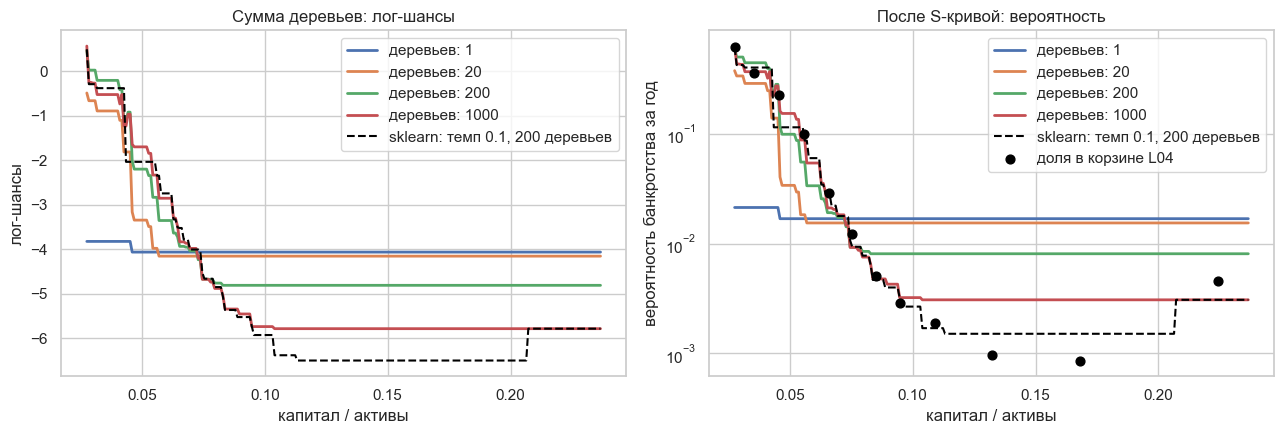

In [53]:
X_cap = train[["c_equity_assets"]]
base_rate = train["y"].mean()
F_cls = np.full(len(train), np.log(base_rate / (1 - base_rate)))    # старт: лог-шансы доли событий
F_cls_grid = np.full(len(cap_grid), F_cls[0])
snap_cls = {}
for m in range(1, 1001):
    p_now = 1 / (1 + np.exp(-F_cls))                                  # текущие вероятности
    tree = DecisionTreeRegressor(max_depth=1).fit(X_cap, y_cap - p_now)   # остаток: факт минус вероятность
    F_cls = F_cls + 0.5 * tree.predict(X_cap)                         # шаг в лог-шансах
    F_cls_grid = F_cls_grid + 0.5 * tree.predict(cap_grid)
    if m in (1, 20, 200, 1000):
        snap_cls[m] = F_cls_grid.copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for m, values in snap_cls.items():
    ax1.plot(cap_grid["c_equity_assets"], values, lw=2, label=f"деревьев: {m}")
    ax2.plot(cap_grid["c_equity_assets"], 1 / (1 + np.exp(-values)), lw=2, label=f"деревьев: {m}")

# sklearn: те же пни, высота ступеньки — шаг Ньютона; темп 0.1, потому что при 0.5 шаги Ньютона здесь расходятся
newton = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200, max_depth=1, early_stopping=False,
                                        random_state=SEED).fit(X_cap, train["y"])
ax1.plot(cap_grid["c_equity_assets"], newton.decision_function(cap_grid), color="black", ls="--", lw=1.5,
         label="sklearn: темп 0.1, 200 деревьев")
ax2.plot(cap_grid["c_equity_assets"], newton.predict_proba(cap_grid)[:, 1], color="black", ls="--", lw=1.5,
         label="sklearn: темп 0.1, 200 деревьев")
ax1.set_title("Сумма деревьев: лог-шансы")
ax1.set_ylabel("лог-шансы")
ax2.scatter(by_bin["equity"], by_bin["share_failed"], color="black", s=40, zorder=5, label="доля в корзине L04")
ax2.set_yscale("log")
ax2.set_title("После S-кривой: вероятность")
ax2.set_ylabel("вероятность банкротства за год")
for ax in (ax1, ax2):
    ax.set_xlabel("капитал / активы")
    ax.legend()
plt.tight_layout()
plt.show()

Наш простой цикл сходится медленно. Первое дерево делит отчёты по капиталу около 4.5 % и едва сдвигает лог-шансы. При низком капитале, где событий много, сумма догоняет доли корзин к 200 деревьям. Справа, где риск мал, даже после 1000 деревьев прогноз стоит на 0.3 %, выше долей L04. Причина в размере шага: у безопасных отчётов остаток $y - p$ порядка сотых, и лог-шансы сдвигаются медленно.

sklearn делит сумму остатков листа на сумму $p(1-p)$ по отчётам листа. Это шаг Ньютона: он учитывает кривизну log loss, и там, где $p$ мало, шаг крупнее. Поэтому sklearn с темпом 0.1 за 200 деревьев проходит правую часть, которую наш цикл не прошёл и за 1000, и снова находит подъём при капитале выше 20 % из §5.1. У шага Ньютона есть обратная сторона: когда делитель крошечный, шаг огромен, и при большом темпе сумма разлетается. Это и случилось в §4.4 при темпе 0.5.